In [1]:
import torch
from torch import nn, optim

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

plt.style.use("dark_background")

In [ ]:
breast_cancer_data = load_breast_cancer(as_frame=True)

X_df = breast_cancer_data.data
y_df = breast_cancer_data.target

data = X_df.copy()
data[y_df.name] = y_df

data.to_csv(r"data\breast_cancer.csv", index=False)

In [5]:
breast_cancer_df = pd.read_csv(r"data\breast_cancer.csv")

print(breast_cancer_df.shape)

(569, 31)


In [6]:
print(breast_cancer_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [7]:
print(breast_cancer_df["target"].unique())
print(breast_cancer_df["target"].value_counts(normalize=True))

[0 1]
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


In [8]:
breast_cancer_df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


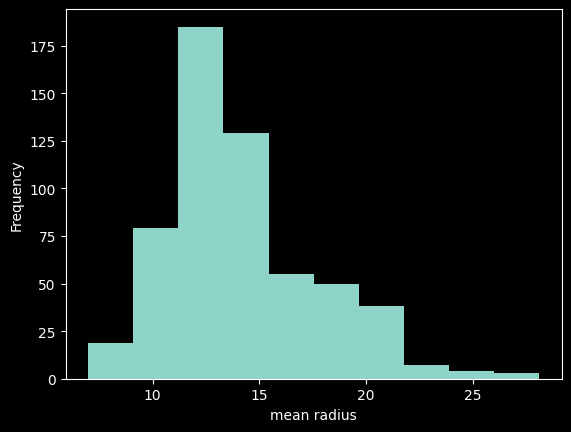

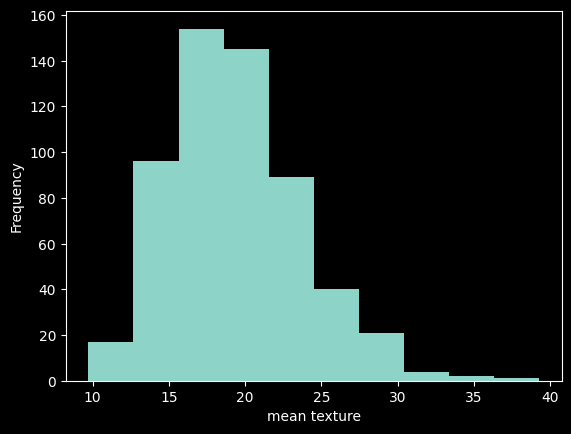

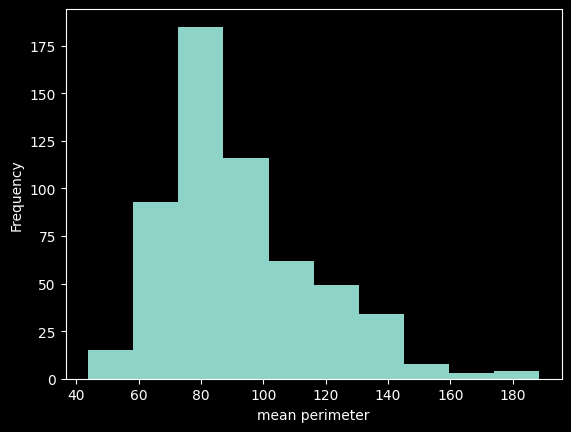

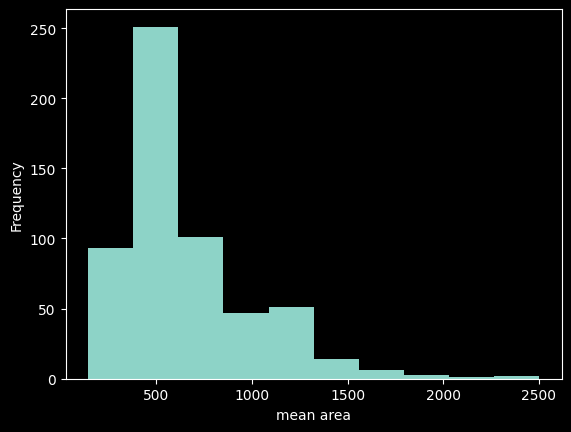

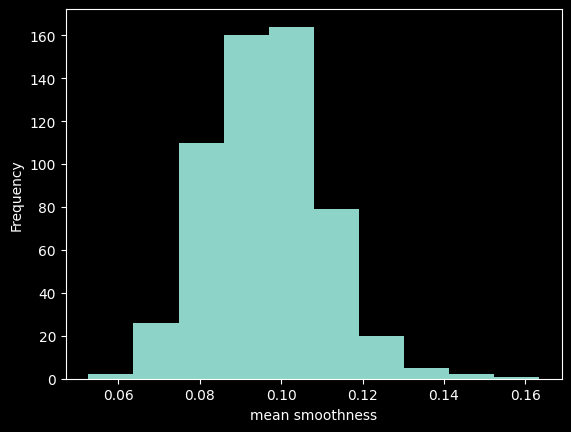

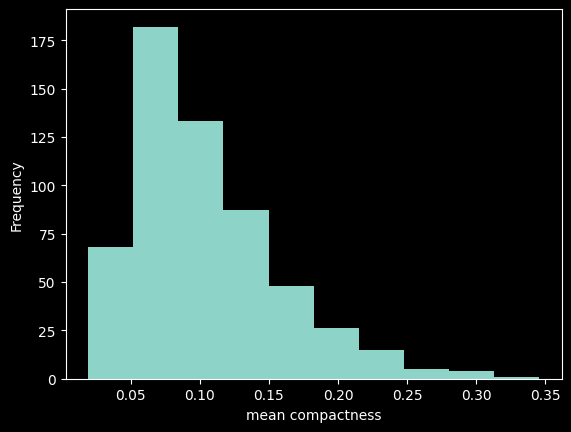

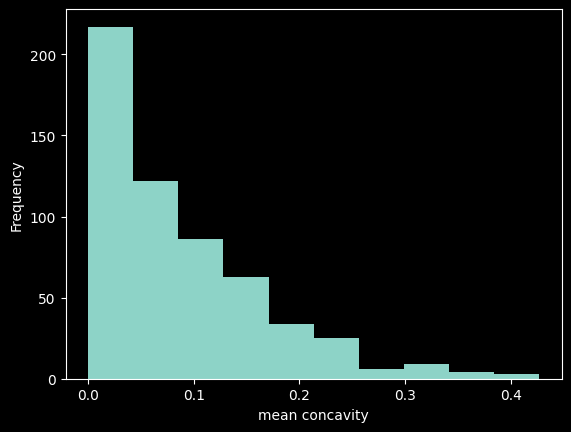

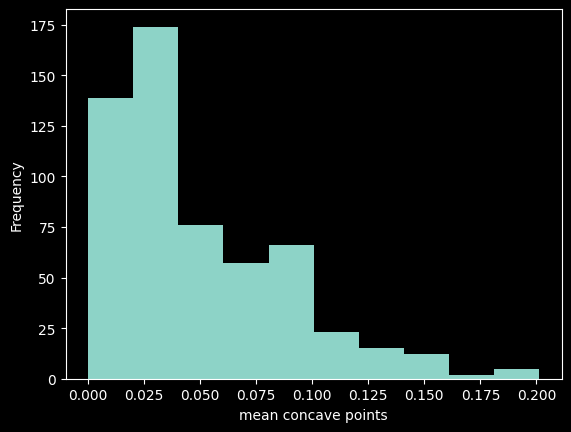

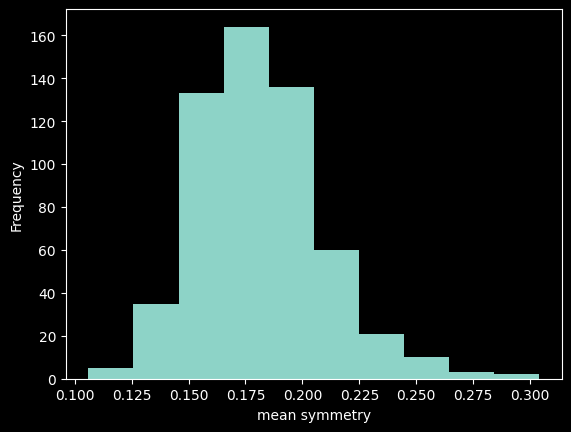

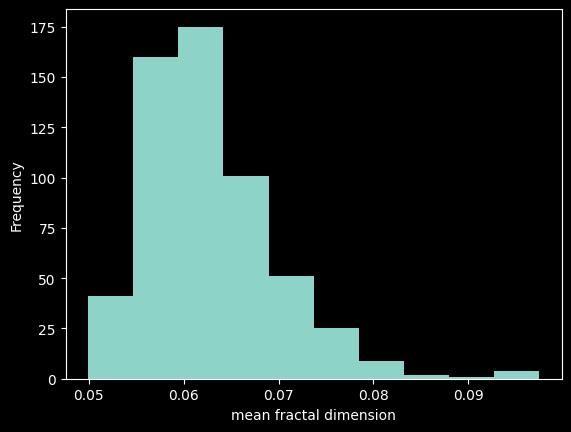

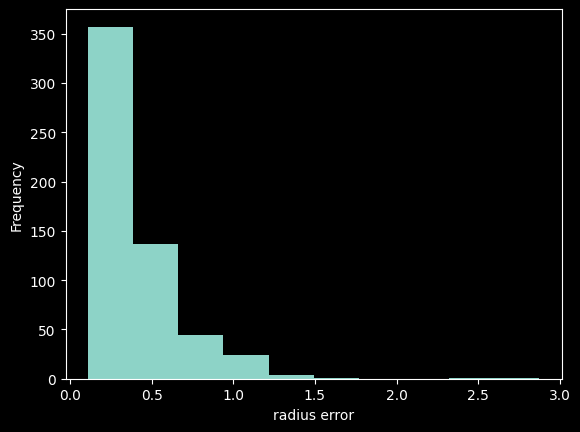

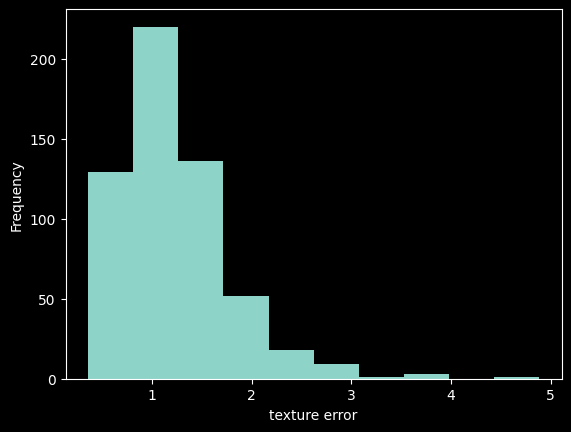

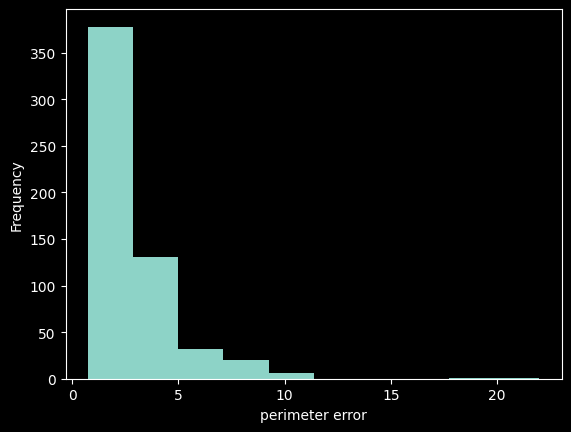

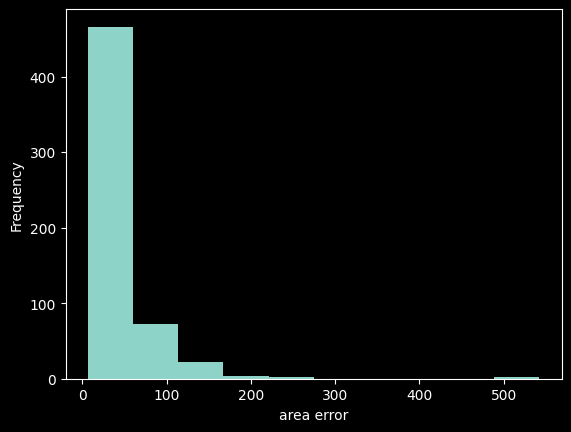

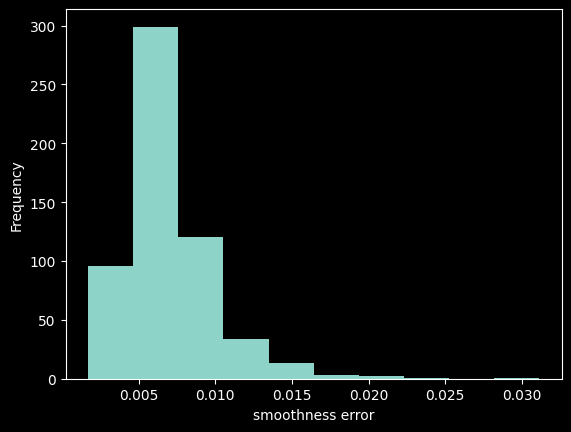

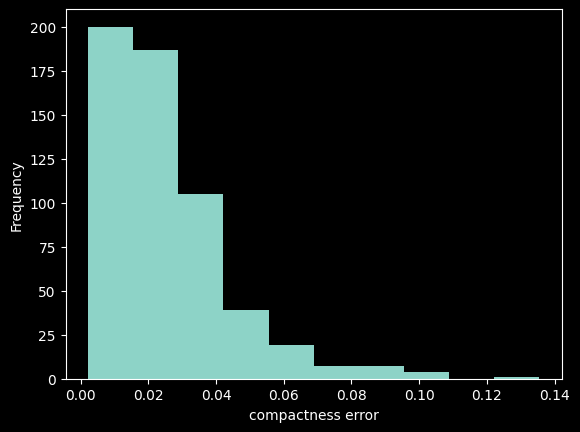

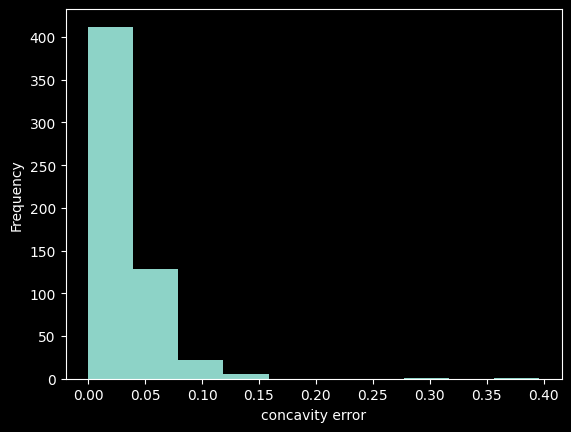

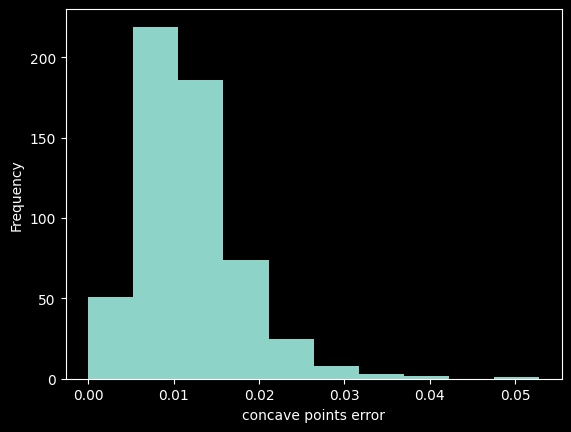

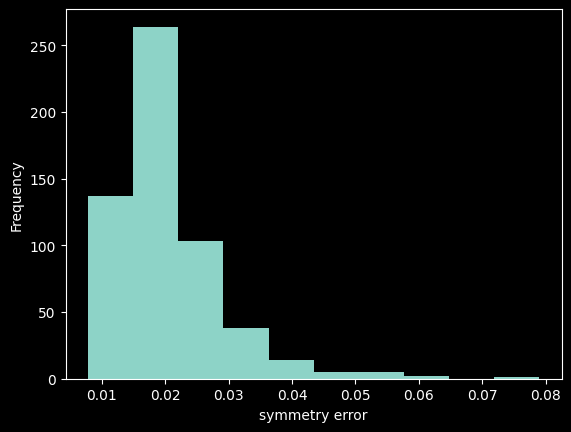

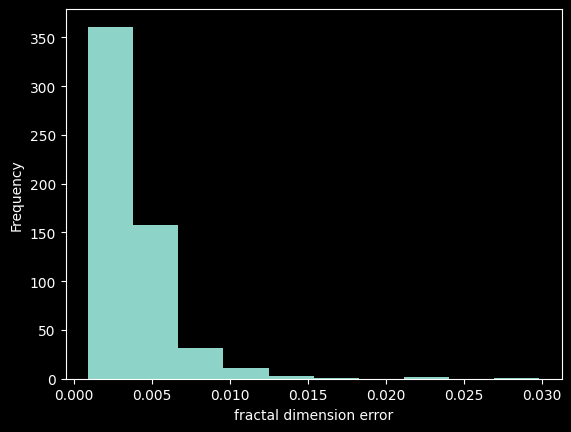

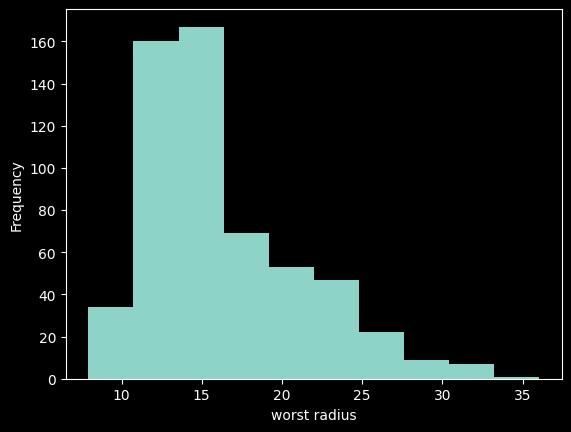

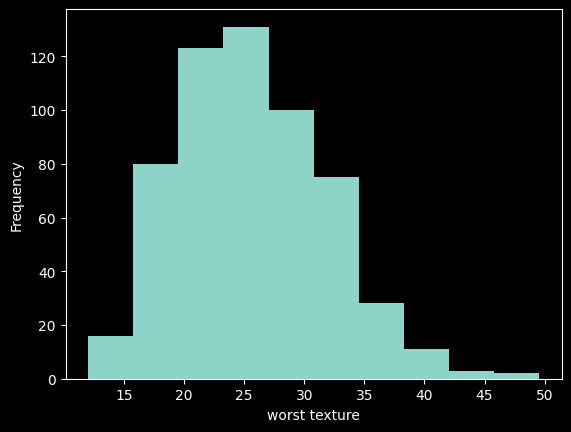

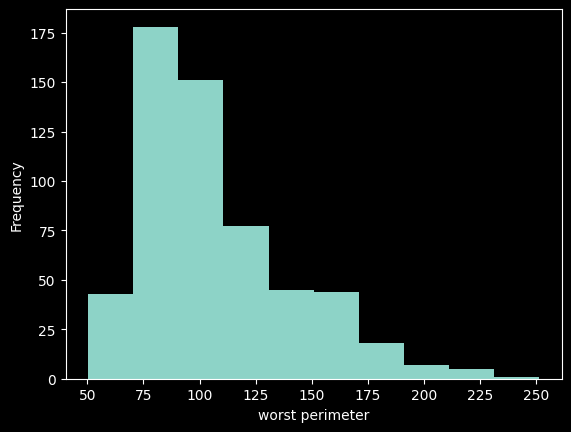

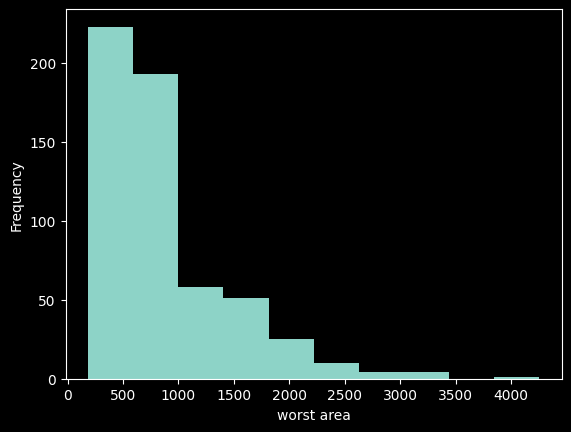

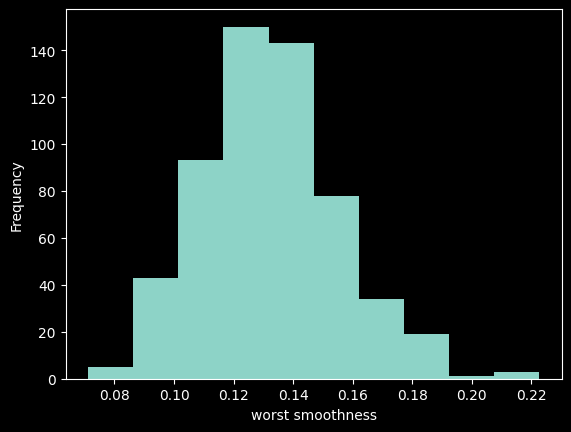

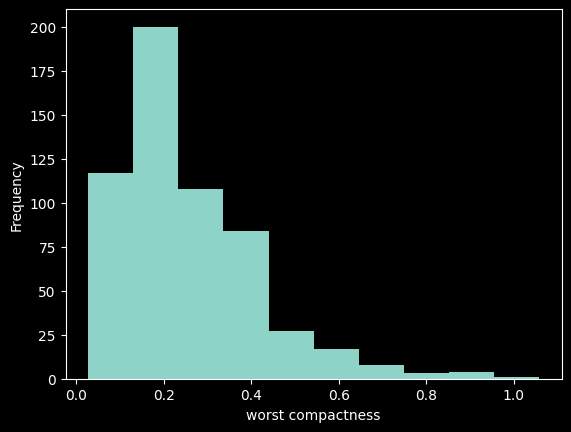

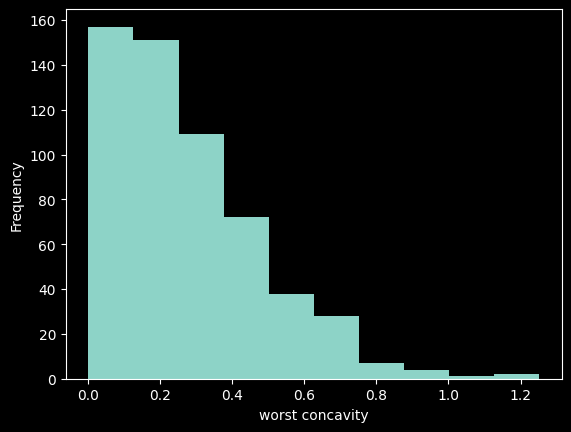

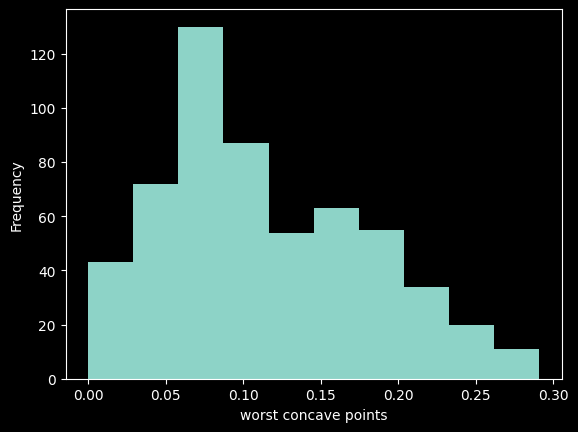

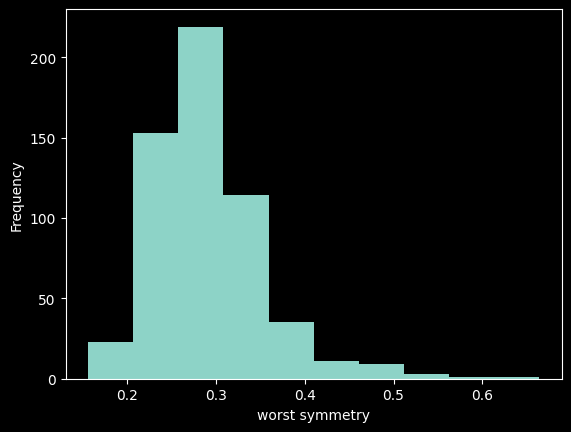

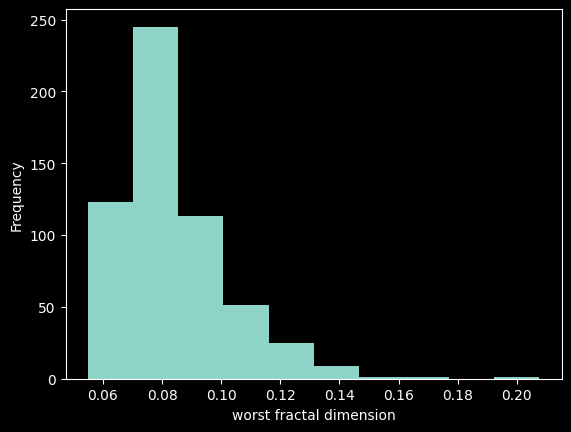

In [9]:
for col in breast_cancer_df.drop("target", axis=1).columns:
    plt.hist(breast_cancer_df[col])
    plt.xlabel(f"{col}")
    plt.ylabel(f"Frequency")
    plt.show()

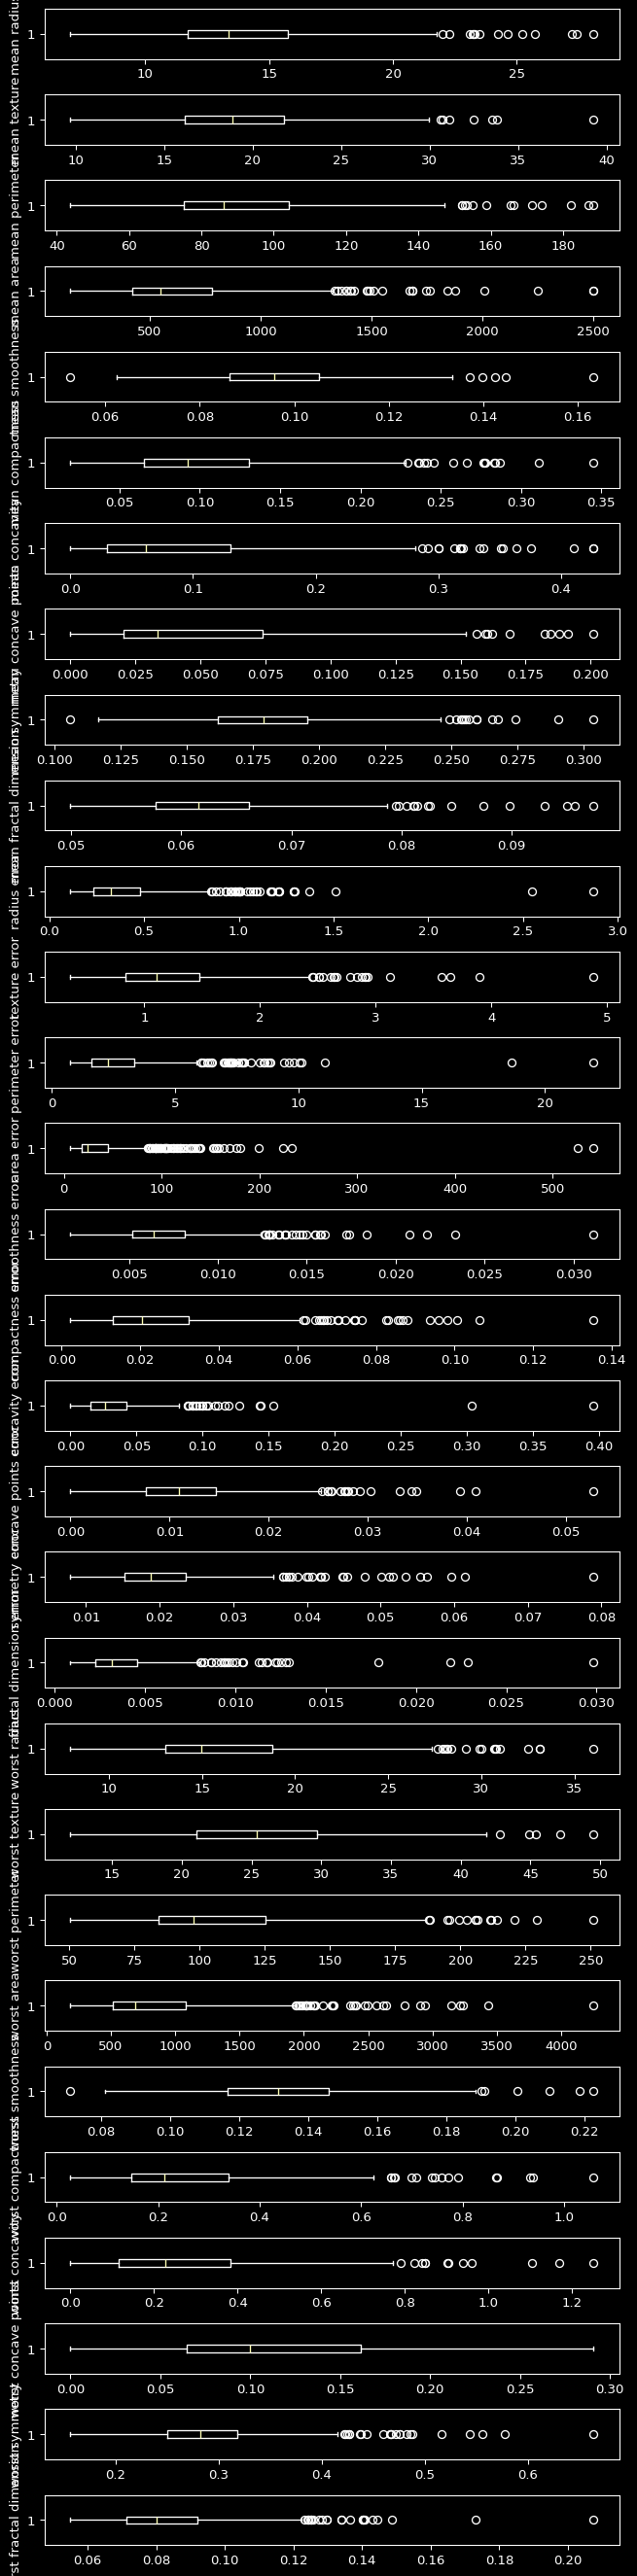

In [ ]:
b_c_df_without_target = breast_cancer_df.drop("target", axis=1)
fig, ax = plt.subplots(len(b_c_df_without_target.columns), 1, figsize=(7, 28), dpi=95)
for i, col in enumerate(b_c_df_without_target):
    ax[i].boxplot(b_c_df_without_target[col], vert=False)
    ax[i].set_ylabel(col)
plt.tight_layout()
plt.savefig(r"data/breast_cancer_df_boxplots_before.png")
plt.show()

In [11]:
from sklearn.preprocessing import PowerTransformer

bc_target = breast_cancer_df["target"]
breast_cancer_df = breast_cancer_df.drop("target", axis=1)

# We will calculate the initial skewness if we apply `log1p` to the entire dataset.
# To automatically determine which variables have been adjusted and which still require the Yeo-Johnson transformation
temp_log_skew = np.log1p(breast_cancer_df).skew()

# We will consider any column with a skewness greater than 1 to be strongly right-skewed.
stubborn_cols = temp_log_skew[temp_log_skew > 1].index.to_list()
good_cols = [col for col in breast_cancer_df.columns if col not in stubborn_cols]

print(f"Columns ready for log1p ({len(good_cols)}):", good_cols)
print(f"Columns requiring Yeo-Johnson ({len(stubborn_cols)}):", stubborn_cols)
print("-" * 50)

bc_df_transformed = breast_cancer_df.copy()

# We apply `log1p` to the columns that responded well to it.
bc_df_transformed[good_cols] = np.log1p(breast_cancer_df[good_cols])

# We apply the Yeo-Johnson transformation to the stubborn columns.
# Setting `standardize=True` results in zero mean and unit variance after the transformation.
pt = PowerTransformer(method="yeo-johnson", standardize=True)
bc_df_transformed[stubborn_cols] = pt.fit_transform(breast_cancer_df[stubborn_cols])

comparison_df = pd.DataFrame({
    'Skewness after log1p (Before YJ)': temp_log_skew[stubborn_cols],
    'Skewness after Yeo-Johnson': bc_df_transformed[stubborn_cols].skew()
})

print("=== Skewness Comparison for stubborn columns ===")
print(comparison_df)

Columns ready for log1p (15): ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean symmetry', 'texture error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concavity', 'worst concave points']
Columns requiring Yeo-Johnson (15): ['mean compactness', 'mean concavity', 'mean concave points', 'mean fractal dimension', 'radius error', 'perimeter error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst compactness', 'worst symmetry', 'worst fractal dimension']
--------------------------------------------------
=== Skewness Comparison for stubborn columns ===
                         Skewness after log1p (Before YJ)  \
mean compactness                                 1.043195   
mean concavity                                   1.206982   
mean concave points                              1.083180   
mean fractal 

In [12]:
bc_df_transformed.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,5.690000e+02,5.690000e+02,5.690000e+02,569.000000,5.690000e+02,...,569.000000,569.000000,569.000000,569.000000,569.000000,5.690000e+02,569.000000,569.000000,5.690000e+02,5.690000e+02
mean,2.691235,2.988199,4.500683,6.365109,0.091914,-4.995028e-17,-1.498508e-16,8.741299e-17,0.166232,-4.557963e-16,...,2.813668,3.257394,4.641377,6.617350,0.124110,1.373633e-16,0.228383,0.106792,-2.747265e-16,-1.273732e-15
std,0.222226,0.209417,0.248328,0.482274,0.012794,1.000880e+00,1.000880e+00,1.000880e+00,0.023036,1.000880e+00,...,0.260391,0.231108,0.288172,0.554173,0.020091,1.000880e+00,0.154498,0.058310,1.000880e+00,1.000880e+00
min,2.077064,2.371178,3.801985,4.973280,0.051292,-2.477742e+00,-1.658319e+00,-1.845392e+00,0.100750,-2.715685e+00,...,2.189416,2.566487,3.939833,5.226821,0.068752,-2.324682e+00,0.000000,0.000000,-3.305164e+00,-2.559634e+00
25%,2.541602,2.843164,4.332968,6.043345,0.082842,-7.729033e-01,-8.254853e-01,-7.732582e-01,0.150057,-7.378980e-01,...,2.639771,3.094672,4.443945,6.246688,0.110288,-6.888821e-01,0.108406,0.062909,-6.260028e-01,-7.236240e-01
50%,2.665143,2.987700,4.468663,6.313729,0.091549,-3.392488e-02,-1.361795e-01,-2.328123e-01,0.164836,-2.013436e-02,...,2.770712,3.273743,4.591680,6.533062,0.123367,-7.279509e-02,0.204328,0.095247,1.365551e-02,-3.606238e-02
75%,2.820188,3.126761,4.654912,6.664026,0.100117,7.221811e-01,8.504764e-01,9.018471e-01,0.178732,6.657754e-01,...,2.985177,3.424914,4.839451,6.989335,0.136278,7.979299e-01,0.324183,0.149626,6.168393e-01,7.041284e-01
max,3.371082,3.695855,5.244389,7.824846,0.151347,2.442063e+00,2.122247e+00,2.141443e+00,0.265436,2.708925e+00,...,3.611998,3.922765,5.530222,8.355850,0.200980,2.487676e+00,0.811819,0.255417,3.250202e+00,2.684781e+00


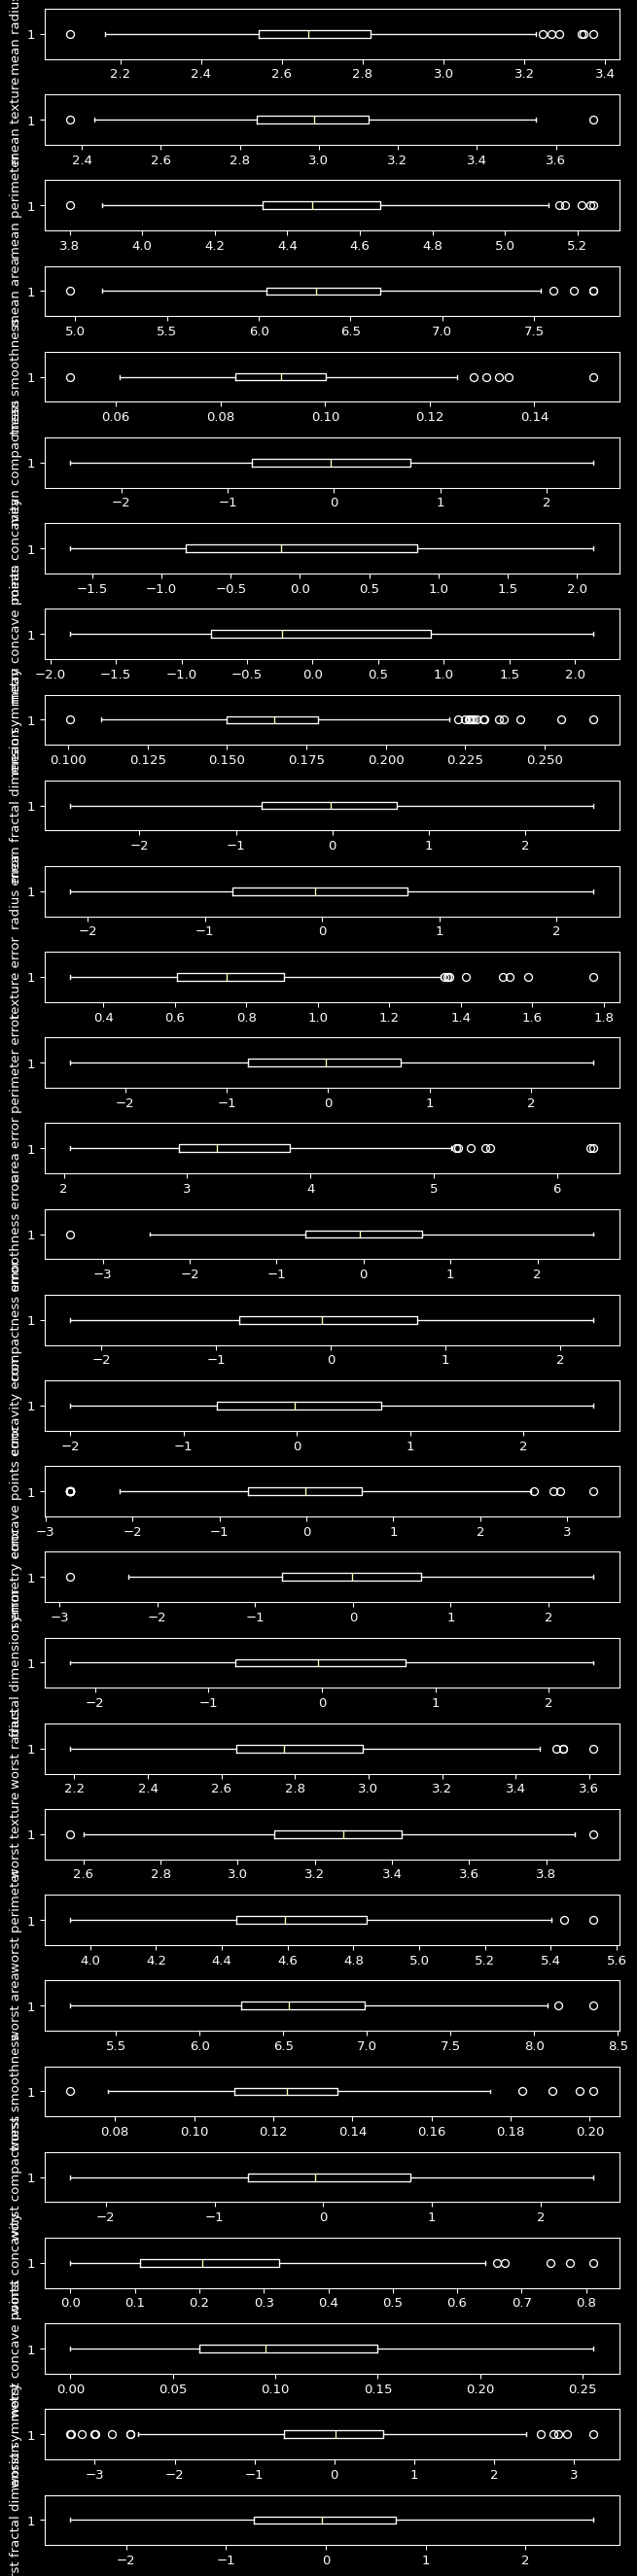

In [ ]:
fig, ax = plt.subplots(len(bc_df_transformed.columns), 1, figsize=(7, 28), dpi=95)
for i, col in enumerate(bc_df_transformed):
    ax[i].boxplot(bc_df_transformed[col], vert=False)
    ax[i].set_ylabel(col)
plt.tight_layout()
plt.savefig(r"data/breast_cancer_df_boxplots_after.png")
plt.show()

In [14]:
bc_df_transformed["target"] = bc_target

In [16]:
X = bc_df_transformed.drop(["target"], axis=1)
y = bc_df_transformed["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report

LoR_model = LogisticRegression(max_iter= 200)
LoR_model.fit(X_train, y_train)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cross_validation = cross_val_score(LoR_model, X_train, y_train, cv=kf)

print(f"Average CV Score: {np.mean(cross_validation)}")

pred_labels = LoR_model.predict(X_test)
accuracy = accuracy_score(y_test, pred_labels)
print(f"Logistic Regression Accuracy: {accuracy}")

pred_probs = LoR_model.predict_proba(X_test)
loss = log_loss(y_test, pred_probs)
print(f"Cross-Entropy Loss (Log Loss): {loss}")

print("Confusion Matrix")
print(confusion_matrix(y_test, pred_labels))

print("Classification Report")
print(classification_report(y_test, pred_labels))

Average CV Score: 0.9736263736263737
Logistic Regression Accuracy: 0.9912280701754386
Cross-Entropy Loss (Log Loss): 0.05937112336728066
Confusion Matrix
[[42  1]
 [ 0 71]]
Classification Report
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        43
           1       0.99      1.00      0.99        71

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



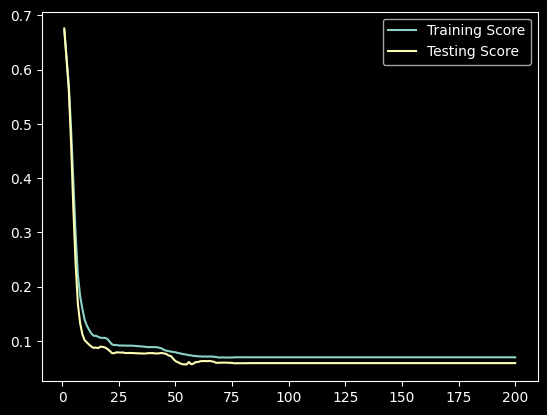

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

max_iter= 200

train_scores = []
test_scores = []

for epoch in range(1, max_iter + 1):
    LoR_model = LogisticRegression(max_iter= epoch)
    LoR_model.fit(X_train, y_train)
    
    preds_train = LoR_model.predict_proba(X_train)
    train_score = log_loss(y_train, preds_train)
    train_scores.append(train_score)
    
    preds_test = LoR_model.predict_proba(X_test)
    test_score = log_loss(y_test, preds_test)
    test_scores.append(test_score)

plt.plot(range(1, max_iter + 1), train_scores, label="Training Score")
plt.plot(range(1, max_iter + 1), test_scores, label="Testing Score")
plt.legend()
plt.show()

In [135]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report

RFC_model = RandomForestClassifier()
RFC_model.fit(X_train, y_train)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cross_validation = cross_val_score(RFC_model, X_train, y_train, cv=kf)

print(f"Average CV Score: {np.mean(cross_validation)}")

pred_labels = RFC_model.predict(X_test)
accuracy = accuracy_score(y_test, pred_labels)
print(f"Random Forest Classifier Accuracy: {accuracy}")

pred_probs = RFC_model.predict_proba(X_test)
loss = log_loss(y_test, pred_probs)
print(f"Cross-Entropy Loss (Log Loss): {loss}")

print("Confusion Matrix")
print(confusion_matrix(y_test, pred_labels))

print("Classification Report")
print(classification_report(y_test, pred_labels))

Average CV Score: 0.9582417582417584
Random Forest Classifier Accuracy: 0.9649122807017544
Cross-Entropy Loss (Log Loss): 0.09567129552152337
Confusion Matrix
[[40  3]
 [ 1 70]]
Classification Report
              precision    recall  f1-score   support

           0       0.98      0.93      0.95        43
           1       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



---
## Dr Mahmoud's Part

In [69]:
breast_cancer_data = load_breast_cancer()

feature_indices = [0, 1]
X = breast_cancer_data.data[:, feature_indices]
y = breast_cancer_data.target

C:\Users\mwafy\AppData\Local\Temp\ipykernel_33684\3265272120.py:5: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X[maligant_mask, 0], X[maligant_mask, 1], c='red', s=80, marker='x', label='Malignant (0)',


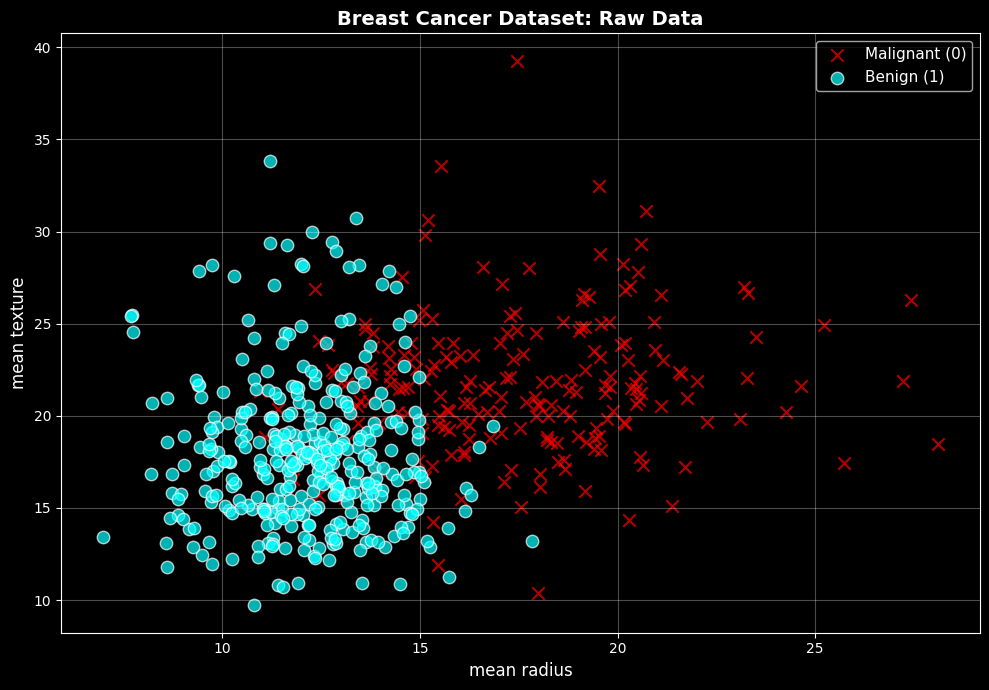

In [70]:
plt.figure(figsize=(10, 7), dpi=100)

# Malignant (0) in red
maligant_mask = (y == 0)
plt.scatter(X[maligant_mask, 0], X[maligant_mask, 1], c='red', s=80, marker='x', label='Malignant (0)',
            edgecolors='white', linewidth=1.5, alpha=0.7)

# Benign (1) in cyan
benign_mask = (y == 1)
plt.scatter(X[benign_mask, 0], X[benign_mask, 1], c='cyan', s=80, marker='o', label='Benign (1)',
            edgecolors='white', linewidth=1, alpha=0.7)

plt.xlabel(breast_cancer_data.feature_names[feature_indices[0]], fontsize=12)
plt.ylabel(breast_cancer_data.feature_names[feature_indices[1]], fontsize=12)
plt.title('Breast Cancer Dataset: Raw Data', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape[0])
print(X_test.shape[0])

# This is why we made "stratify" in the splitting
# To split the proportions between the training and test set correctly according to the proportions in y
print(np.unique(y_train, return_counts=True))
print(np.unique(y_test,  return_counts=True))

print(f"\nTraining set class distribution:")
unique, counts = np.unique(y_train, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  {breast_cancer_data.target_names[label]}: {count} samples")

455
114
(array([0, 1]), array([170, 285]))
(array([0, 1]), array([42, 72]))

Training set class distribution:
  malignant: 170 samples
  benign: 285 samples


### Feature Standardization

**Why z-score (standardize)?**
- Features have different scales (radius: 6-28, texture: 9-40)
- Gradient descent works better when features are on similar scales
- We'll use **standardization**: transform each feature to have mean=0 and std=1

**Formula:** $x_{\text{zscored}} = \frac{x - \mu}{\sigma}$

**Important:** We fit the scaler on training data only, then apply to both train and test!

In [72]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before normalization:")
print(X_train.mean(axis=0))
print(X_train.std(axis=0))

print("\nAfter normalization:")
print(X_train_scaled.mean(axis=0))
print(X_train_scaled.std(axis=0))

Before normalization:
[14.06721319 19.24736264]
[3.49553212 4.40044714]

After normalization:
[-4.31742554e-15  2.24606658e-15]
[1. 1.]


---

<div dir="rtl" style="text-align: right; font-size: 20px; font-weight: bold; margin: 20px 0;">
Part 3: Perceptron Algorithm
</div>

## Algorithm 1: Perceptron (Lecture 5)

### What is the Perceptron?

The **Perceptron** is the simplest neural network - a single neuron!

**How it works:**
1. Compute: $z = w_1 x_1 + w_2 x_2 + b$ (linear combination)
2. Predict: $\hat{y} = \begin{cases} +1 & \text{if } z \geq 0 \\ -1 & \text{if } z < 0 \end{cases}$ (step activation)
3. Update weights **only if wrong**: $w = w + \eta (y - \hat{y}) x$

**Key difference from Adaline:**
- Uses **step function** (hard decision: -1 or +1)
- Updates weights only when misclassified
- Counts **number of errors** (not continuous cost)

**Note:** Perceptron uses labels **-1** and **+1** (not 0 and 1)

In [73]:
y_train_perceptron = np.where(y_train == 0, -1, 1)
y_test_perceptron = np.where(y_test == 0, -1, 1)

print("Original labels (0/1):", y_train[:10])
print("Perceptron labels (-1/+1):", y_train_perceptron[:10])

Original labels (0/1): [1 0 1 1 1 1 1 1 1 1]
Perceptron labels (-1/+1): [ 1 -1  1  1  1  1  1  1  1  1]


In [74]:
np.random.seed(42)
w1 = np.random.randn()
w2 = np.random.randn()
b = np.random.randn()

# Hyperparameters
lr = 0.01
epochs = 100
errors = np.zeros(epochs)

for epoch in range(epochs):
    error_count = 0
    for i in range(len(X_train_scaled)):
        # Linear prediction equation
        z = w1 * X_train_scaled[i, 0] + w2 * X_train_scaled[i, 1] + b
        
        # Step activation function
        y_hat = 1 if z >= 0 else -1
        
        w_gradinet = - (y_train_perceptron[i] - y_hat) * X_train_scaled[i]
        b_gradient = - (y_train_perceptron[i] - y_hat)
        
        if y_hat != y_train_perceptron[i]:
            w1 -= lr * w_gradinet[0]
            w2 -= lr * w_gradinet[1]
            b -= lr * b_gradient
            error_count += 1
            
    errors[epoch] = error_count
    
    if error_count == 0:
        print(f"Converged at epoch {epoch + 1}!")
        break

print(f"\nFinal weights:")
print(f"  w1 = {w1:.4f}")
print(f"  w2 = {w2:.4f}")
print(f"  b  = {b:.4f}")


Final weights:
  w1 = -0.0499
  w2 = -0.0415
  b  = 0.0077


C:\Users\mwafy\AppData\Local\Temp\ipykernel_33684\1968751845.py:5: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax1.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1],


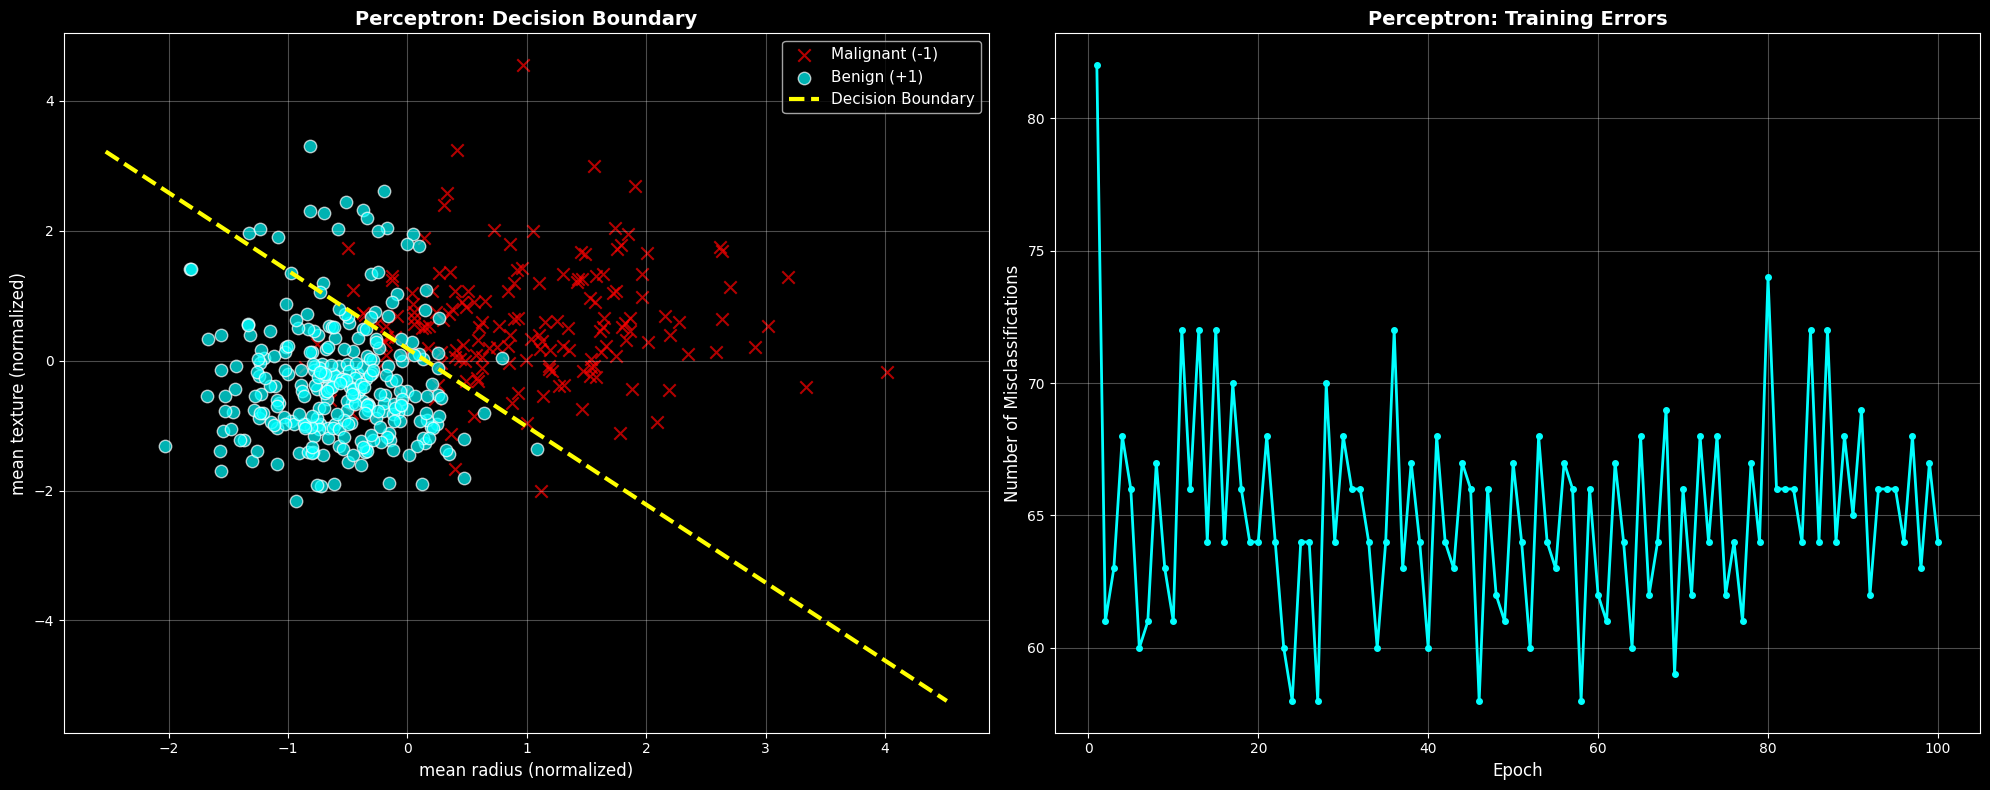

In [75]:
# Create visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), dpi=100)

# Plot 1: Decision boundary
ax1.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1],
            c='red', s=80, marker='x', label='Malignant (-1)',
            edgecolors='white', linewidth=1.5, alpha=0.7)
ax1.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1],
            c='cyan', s=80, marker='o', label='Benign (+1)',
            edgecolors='white', linewidth=1, alpha=0.7)

# Plot decision boundary: w1*x1 + w2*x2 + b = 0 => x2 = -(w1*x1 + b)/w2
x1_vals = np.linspace(X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5, 100)
x2_vals = -(w1 * x1_vals + b) / w2
ax1.plot(x1_vals, x2_vals, 'yellow', linewidth=3, label='Decision Boundary', linestyle='--')

ax1.set_xlabel(breast_cancer_data.feature_names[feature_indices[0]] + ' (normalized)', fontsize=12)
ax1.set_ylabel(breast_cancer_data.feature_names[feature_indices[1]] + ' (normalized)', fontsize=12)
ax1.set_title('Perceptron: Decision Boundary', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Training errors
ax2.plot(range(1, epoch + 2), errors[:epoch + 1], 'cyan', linewidth=2, marker='o', markersize=4)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Number of Misclassifications', fontsize=12)
ax2.set_title('Perceptron: Training Errors', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [76]:
train_preds = [1 if w1 * X_train_scaled[i, 0] + w2 * X_train_scaled[i, 1] + b >= 0 else -1 for i in range(len(X_train_scaled))]
train_accuracy = np.mean(train_preds == y_train_perceptron) * 100

test_preds = [1 if w1 * X_test_scaled[i, 0] + w2 * X_test_scaled[i, 1] + b >= 0 else -1 for i in range(len(X_test_scaled))]
test_accuracy = np.mean(test_preds == y_test_perceptron) * 100

print(f"Training Accuracy: {train_accuracy:.2f}%")
print(f"Testing Accuracy:  {test_accuracy:.2f}%")


Training Accuracy: 87.91%
Testing Accuracy:  85.09%


---

<div dir="rtl" style="text-align: right; font-size: 20px; font-weight: bold; margin: 20px 0;">
Part 4: Adaline Algorithm
</div>

## Algorithm 2: Adaline - Adaptive Linear Neuron (Lecture 5)

### What is Adaline?

**Adaline** improves on the Perceptron by using a **continuous cost function**!

**How it works:**
1. Compute: $z = w_1 x_1 + w_2 x_2 + b$ (linear activation)
2. Cost: MSE
3. Update weights using **gradient descent** (always updates, not just when wrong)

**Key differences from Perceptron:**
- Uses **linear activation** (continuous output)
- Updates weights with GD
- Minimizes **continuous cost** (MSE, not error count)
- More stable convergence

**Note:** Adaline also uses labels **-1** and **+1**

In [77]:
y_train_adaline = np.where(y_train == 0, -1, 1)
y_test_adaline = np.where(y_test == 0, -1, 1)

In [78]:
np.random.seed(42)
w1_adaline = np.random.randn()
w2_adaline = np.random.randn()
b_adaline = np.random.randn()

# Hyperparameters
lr = 0.1
epochs = 2000
cost_history = np.zeros(epochs)

for epoch in range(epochs):
    error_count = 0
    
    # Linear prediction equation
    y_hat = w1_adaline * X_train_scaled[:, 0] + w2_adaline * X_train_scaled[:, 1] + b_adaline
    
    error = y_hat - y_train
    w_gradinet = (1 / len(X_train_scaled)) * np.dot(error, X_train_scaled)
    b_gradient = (1 / len(X_train_scaled)) * np.sum(error)
    
    w1_adaline -= lr * w_gradinet[0]
    w2_adaline -= lr * w_gradinet[1]
    b_adaline -= lr * b_gradient
    
    cost_history[epoch] = 0.5 * np.mean(error ** 2)

print(f"\nFinal weights:")
print(f"  w1 = {w1_adaline:.4f}")
print(f"  w2 = {w2_adaline:.4f}")
print(f"  b  = {b_adaline:.4f}")


Final weights:
  w1 = -0.3240
  w2 = -0.0961
  b  = 0.6264


In [79]:
adaline_train = w1_adaline * X_train_scaled[:, 0] + w2_adaline * X_train_scaled[:, 1] + b_adaline

adaline_train_preds = np.where(adaline_train >= 0, 1, -1)
adaline_train_accuracy = np.mean(adaline_train_preds == y_train_perceptron) * 100

adaline_test = w1_adaline * X_test_scaled[:, 0] + w2_adaline * X_test_scaled[:, 1] + b_adaline

adaline_test_preds = np.where(adaline_test >= 0, 1, -1)
adaline_test_accuracy = np.mean(adaline_test_preds == y_test_perceptron) * 100

print(f"Training Accuracy: {adaline_train_accuracy:.2f}%")
print(f"Testing Accuracy:  {adaline_test_accuracy:.2f}%")

Training Accuracy: 70.55%
Testing Accuracy:  71.05%


### Adaline Training

Run this cell and observe:
- How cost decreases smoothly (unlike step-like errors in Perceptron)
- Matrix operations (more efficient than loops)
- The decision boundary

In [80]:
X_train_bias = np.column_stack([np.ones(len(X_train_scaled)), X_train_scaled])
X_test_bias = np.column_stack([np.ones(len(X_test_scaled)), X_test_scaled])

np.random.seed(42)
w_adaline = np.random.rand(3) * 0.01

lr_adaline = 0.1
epochs_adaline = 2000
cost_history = np.zeros(epochs_adaline)

for epoch in range(epochs_adaline):
    z = X_train_bias @ w_adaline
    
    error = z - y_train_adaline
    
    w_gradient = (1 / len(X_train_scaled)) * (X_train_bias.T @ error)
    w_adaline -= lr_adaline * w_gradient
    
    cost_history[epoch] = 0.5 * np.mean(error ** 2)

b_adaline = w_adaline[0]
w1_adaline = w_adaline[1]
w1_adaline = w_adaline[2]

print(f"Final weights:")
print(f"  w1 = {w1_adaline:.4f}")
print(f"  w2 = {w2_adaline:.4f}")
print(f"  b  = {b_adaline:.4f}")
print(f"\nFinal cost (SSE): {cost_history[-1]:.6f}")

Final weights:
  w1 = -0.1923
  w2 = -0.0961
  b  = 0.2527

Final cost (SSE): 0.200451


C:\Users\mwafy\AppData\Local\Temp\ipykernel_33684\1029644281.py:5: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax1.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1],


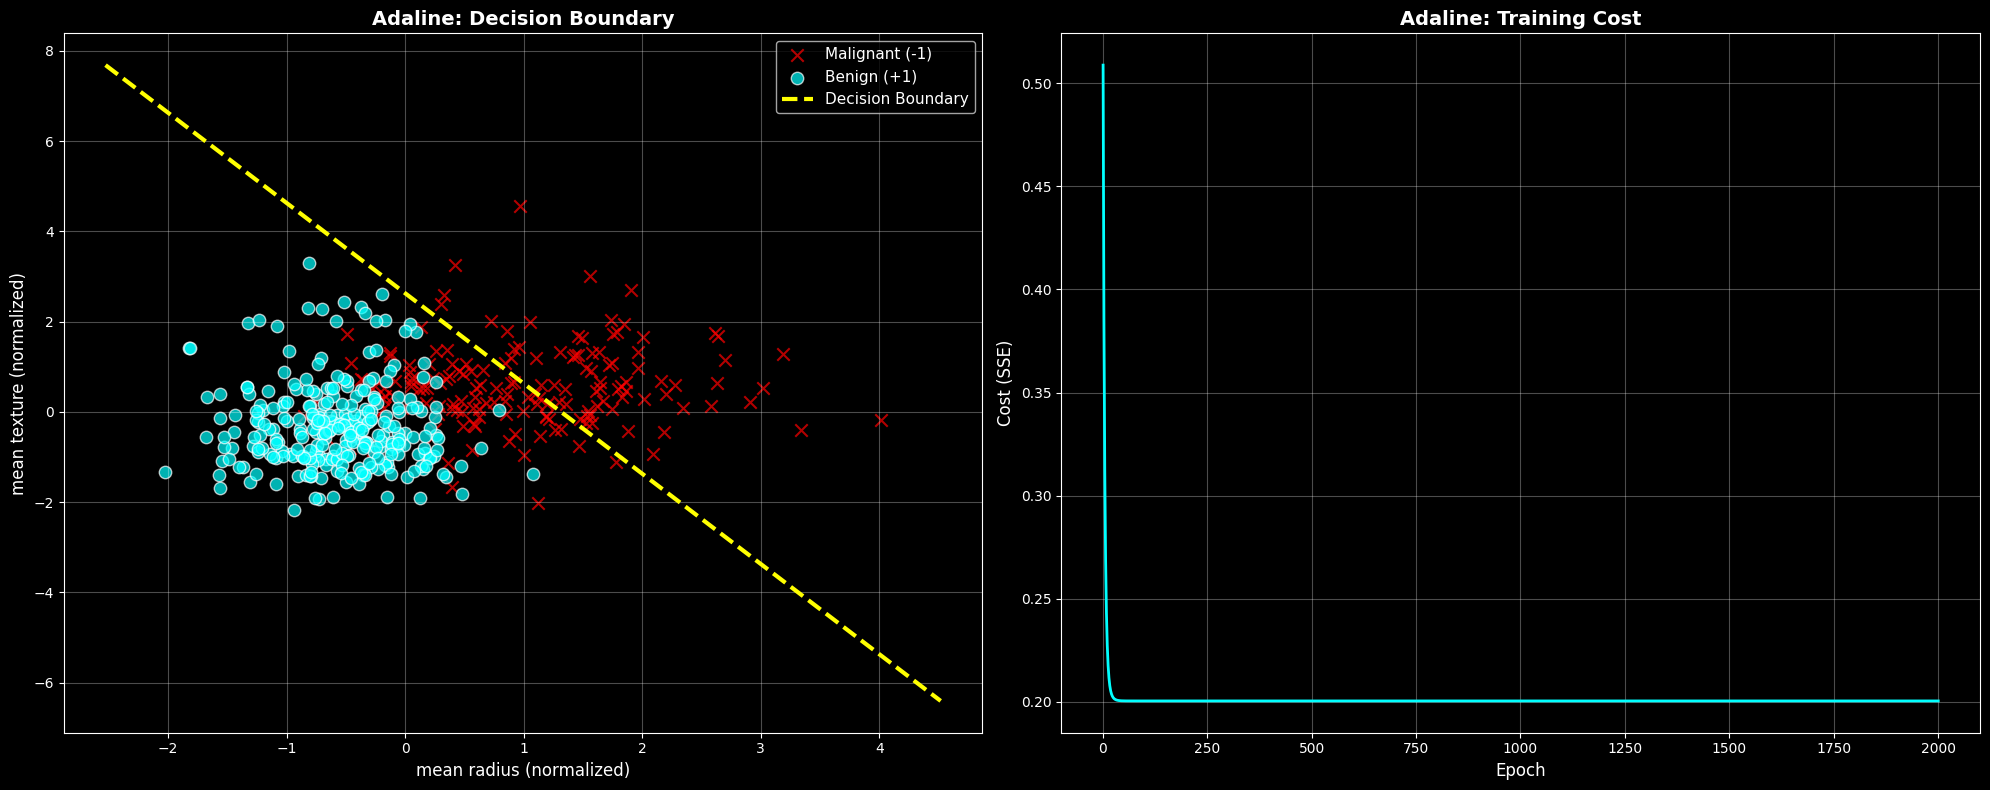

Notice: Cost decreases smoothly (unlike step-like errors in Perceptron)!


In [81]:
# Create visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), dpi=100)

# Plot 1: Decision boundary
ax1.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1],
            c='red', s=80, marker='x', label='Malignant (-1)',
            edgecolors='white', linewidth=1.5, alpha=0.7)
ax1.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1],
            c='cyan', s=80, marker='o', label='Benign (+1)',
            edgecolors='white', linewidth=1, alpha=0.7)

# Plot decision boundary
x1_vals = np.linspace(X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5, 100)
x2_vals = -(w1_adaline * x1_vals + b_adaline) / w2_adaline
ax1.plot(x1_vals, x2_vals, 'yellow', linewidth=3, label='Decision Boundary', linestyle='--')

ax1.set_xlabel(breast_cancer_data.feature_names[feature_indices[0]] + ' (normalized)', fontsize=12)
ax1.set_ylabel(breast_cancer_data.feature_names[feature_indices[1]] + ' (normalized)', fontsize=12)
ax1.set_title('Adaline: Decision Boundary', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Cost over epochs
ax2.plot(range(1, epochs_adaline + 1), cost_history, 'cyan', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Cost (SSE)', fontsize=12)
ax2.set_title('Adaline: Training Cost', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Notice: Cost decreases smoothly (unlike step-like errors in Perceptron)!")

In [82]:
# Training accuracy (use step function for final prediction)
train_predictions_adaline = np.where(X_train_bias @ w_adaline >= 0, 1, -1)
train_accuracy_adaline = np.mean(train_predictions_adaline == y_train_adaline) * 100

# Testing accuracy
test_predictions_adaline = np.where(X_test_bias @ w_adaline >= 0, 1, -1)
test_accuracy_adaline = np.mean(test_predictions_adaline == y_test_adaline) * 100

print("="*60)
print("ADALINE RESULTS")
print("="*60)
print(f"Training Accuracy: {train_accuracy_adaline:.2f}%")
print(f"Testing Accuracy:  {test_accuracy_adaline:.2f}%")
print(f"\nFinal Cost (SSE): {cost_history[-1]:.6f}")
print("="*60)

ADALINE RESULTS
Training Accuracy: 88.35%
Testing Accuracy:  89.47%

Final Cost (SSE): 0.200451


---

## Algorithm 3: Logistic Regression (Lecture 6)

### What is Logistic Regression?

**Logistic Regression** is the most popular binary classification algorithm!

**How it works:**
1. Compute: $z = w_1 x_1 + w_2 x_2 + b$ (linear combination)
2. Apply: $\sigma(z) = \frac{1}{1 + e^{-z}}$ (sigmoid activation)
3. Output: Probability between 0 and 1
4. Cost: Cross-Entropy
5. Predict: $\hat{y} = 1$ if $\sigma(z) \geq 0.5$, else $\hat{y} = 0$

**Key differences:**
- Uses **sigmoid activation** (outputs probability)
- Uses **cross-entropy cost** (not MSE) remember when we talked about convex and non-convex cost surfaces in the lecture
- Labels are **0** and **1** (not -1 and +1)
- Gives probabilistic predictions!

### Why Sigmoid?

The **sigmoid function** squashes any number to the range [0, 1]:
- Large positive $z$ → $\sigma(z) \approx 1$ (high confidence: class 1)
- Large negative $z$ → $\sigma(z) \approx 0$ (high confidence: class 0)
- $z = 0$ → $\sigma(z) = 0.5$ (uncertain .. on the boundary)

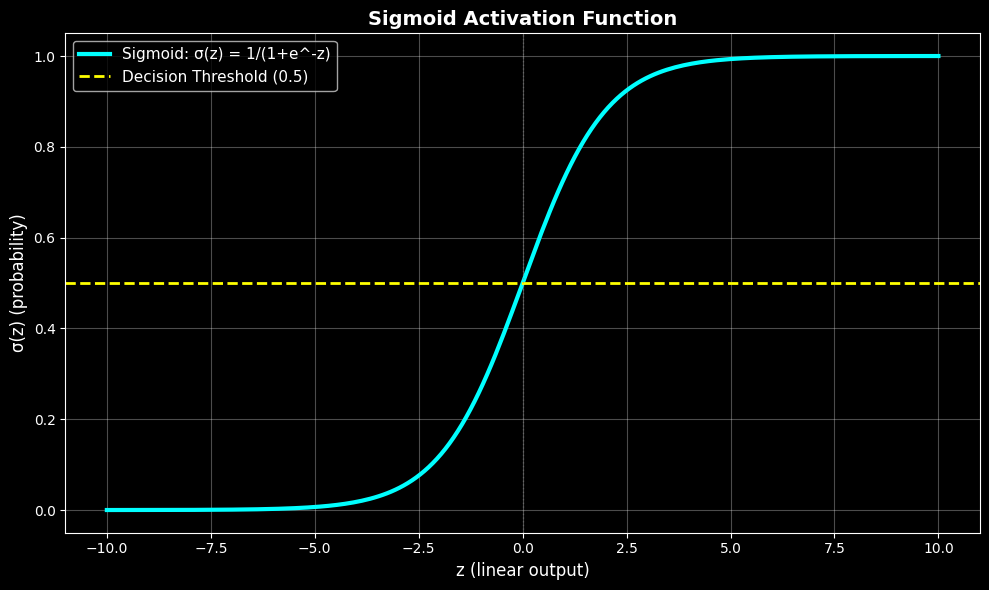

Sigmoid transforms linear output z to probability:
  z = -5 → σ(z) = 0.0067 (very likely class 0)
  z =  0 → σ(z) = 0.5000 (uncertain)
  z = +5 → σ(z) = 0.9933 (very likely class 1)


In [83]:
# Visualize the sigmoid function
z_vals = np.linspace(-10, 10, 200)
sigmoid_vals = 1 / (1 + np.exp(-z_vals))

plt.figure(figsize=(10, 6), dpi=100)
plt.plot(z_vals, sigmoid_vals, 'cyan', linewidth=3, label='Sigmoid: σ(z) = 1/(1+e^-z)')
plt.axhline(y=0.5, color='yellow', linestyle='--', linewidth=2, label='Decision Threshold (0.5)')
plt.axvline(x=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)
plt.xlabel('z (linear output)', fontsize=12)
plt.ylabel('σ(z) (probability)', fontsize=12)
plt.title('Sigmoid Activation Function', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("Sigmoid transforms linear output z to probability:")
print(f"  z = -5 → σ(z) = {1/(1+np.exp(5)):.4f} (very likely class 0)")
print(f"  z =  0 → σ(z) = {1/(1+np.exp(0)):.4f} (uncertain)")
print(f"  z = +5 → σ(z) = {1/(1+np.exp(-5)):.4f} (very likely class 1)")

### Logistic Regression Training

Run this cell and observe:
- How cross-entropy cost decreases
- The probabilistic decision boundary
- Final predictions with probabilities

In [84]:
np.random.seed(42)
w_LoR = np.random.rand(2) * 0.01
b_LoR = np.random.rand() * 0.01

lr_LoR = 0.1
epochs = 1000
cost_history_LoR = np.zeros(epochs)

def sigmoid(x):
    res = 1 / (1 + np.exp(-x))
    return res

for epoch in range(epochs):
    z = np.dot(X_train_scaled, w_LoR) + b_LoR
    y_hat = sigmoid(z)
    
    error = y_hat - y_train
    w_lor_grads = (1 / len(X_train_scaled)) * np.dot(error, X_train_scaled)
    b_lor_grads = (1 / len(X_train_scaled)) * np.sum(error)
    
    w_LoR -= lr_LoR * w_lor_grads
    b_LoR -= lr_LoR * b_lor_grads
    
    bce_loss = - np.mean(y_train * np.log(y_hat + 1e-10) + (1 - y_train) * np.log(1 - y_hat + 1e-10))
    cost_history_LoR[epoch] = bce_loss

w1_LoR = w_LoR[0]
w2_LoR = w_LoR[1]

print(f"Final weights:")
print(f"  w1 = {w1_LoR:.4f}")
print(f"  w2 = {w2_LoR:.4f}")
print(f"  b  = {b_LoR:.4f}")
print(f"\nFinal cost (Cross-Entropy): {cost_history_LoR[-1]:.6f}")

Final weights:
  w1 = -3.3677
  w2 = -0.8514
  b  = 0.6754

Final cost (Cross-Entropy): 0.256953


In [85]:
# Training
linear_train_LoR = np.dot(X_train_scaled, w_LoR) + b_LoR
probs_train_LoR = sigmoid(linear_train_LoR)

train_preds_LoR = np.where(probs_train_LoR >= 0.5, 1, 0)
train_accuracy_LoR = np.mean(train_preds_LoR == y_train) * 100

# Testing
linear_test_LoR = np.dot(X_test_scaled, w_LoR) + b_LoR
probs_test_LoR = sigmoid(linear_test_LoR)

test_preds_LoR = np.where(probs_test_LoR >= 0.5, 1, 0)
test_accuracy_LoR = np.mean(test_preds_LoR == y_test) * 100

print("="*60)
print("LOGISTIC REGRESSION RESULTS")
print("="*60)
print(f"Training Accuracy: {train_accuracy_LoR:.2f}%")
print(f"Testing Accuracy:  {test_accuracy_LoR:.2f}%")
print("="*60)

LOGISTIC REGRESSION RESULTS
Training Accuracy: 89.45%
Testing Accuracy:  87.72%


C:\Users\mwafy\AppData\Local\Temp\ipykernel_33684\1865224549.py:16: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax1.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1], c='red', s=80, marker='x', label='Malignant (0)', edgecolors='white', linewidth=1.5, alpha=0.9)


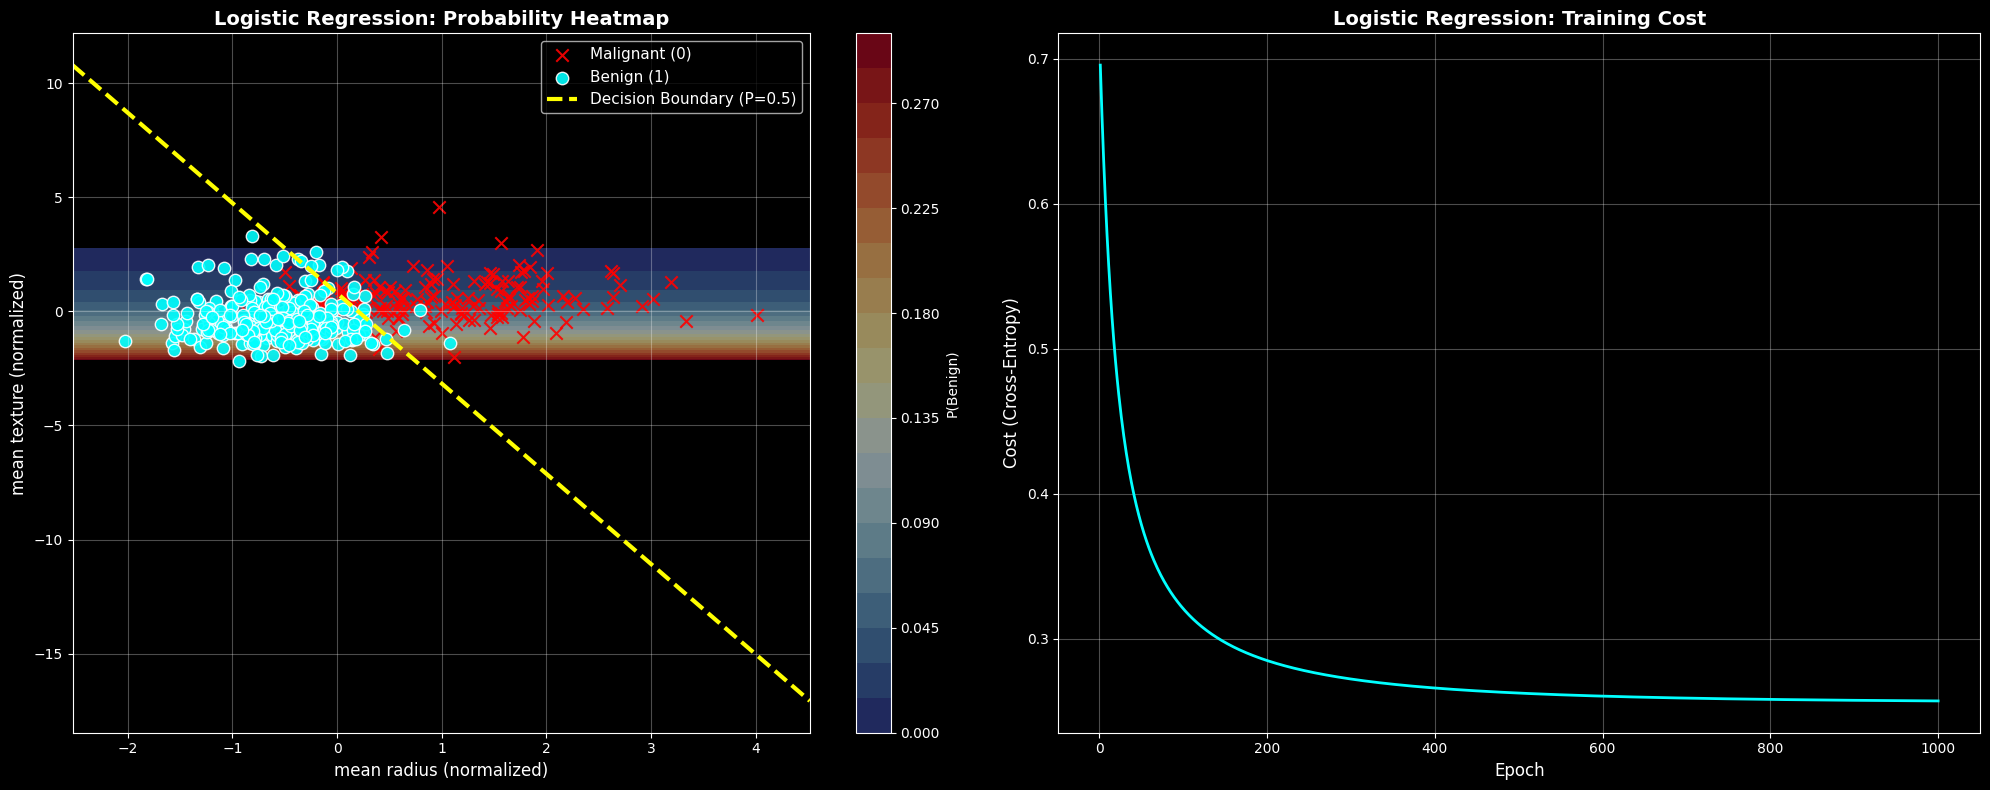

In [86]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), dpi=100)

x1_grid = np.linspace(X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5, 200)
x2_grid = np.linspace(X_test_scaled[:, 1].min() - 0.5, X_test_scaled[:, 1].max() + 0.5, 200)
X1_mesh, X2_mesh = np.meshgrid(x1_grid, x2_grid)
X_grid = np.column_stack([np.ones(X1_mesh.ravel().shape[0]), X2_mesh.ravel()])

z_grid = np.dot(X_grid, w_LoR) + b_LoR
prob_grid = sigmoid(z_grid)

# Plot 1: Decision boundary with probability heatmap
contour = ax1.contourf(X1_mesh, X2_mesh, prob_grid.reshape(X1_mesh.shape), 
                        levels=20, cmap='RdYlBu_r', alpha=0.6)
plt.colorbar(contour, ax=ax1, label='P(Benign)')

ax1.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1], c='red', s=80, marker='x', label='Malignant (0)', edgecolors='white', linewidth=1.5, alpha=0.9)
ax1.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1], c='cyan', s=80, marker='o', label='Benign (1)', edgecolors='white', linewidth=1, alpha=0.9)

x1_vals = np.linspace(X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5, 100)
x2_vals = -(w1_LoR * x1_vals + b_LoR) / w2_LoR

ax1.plot(x1_vals, x2_vals, 'yellow', linewidth=3, label='Decision Boundary (P=0.5)', linestyle='--')

ax1.set_xlabel(breast_cancer_data.feature_names[feature_indices[0]] + ' (normalized)', fontsize=12)
ax1.set_ylabel(breast_cancer_data.feature_names[feature_indices[1]] + ' (normalized)', fontsize=12)
ax1.set_title('Logistic Regression: Probability Heatmap', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Cost over epochs
ax2.plot(range(1, epoch + 2), cost_history_LoR[:epoch + 1], 'cyan', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Cost (Cross-Entropy)', fontsize=12)
ax2.set_title('Logistic Regression: Training Cost', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Algorithm 4: Logistic Regression with PyTorch

In [88]:
import torch
from torch import nn, optim

X_train_torch = torch.FloatTensor(X_train_scaled)
y_train_torch = torch.FloatTensor(y_train).unsqueeze(1)
X_test_torch = torch.FloatTensor(X_test_scaled)
y_test_torch = torch.FloatTensor(y_test).unsqueeze(1)

class LogisticRegression(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        z = self.linear(x)
        h = self.sigmoid(z)
        return h

torch.manual_seed(42)
model_pytorch = LogisticRegression(input_dim=2)

criterion = nn.BCELoss()
optimizer = optim.SGD(model_pytorch.parameters(), lr=0.1)

epochs = 1000
cost_history_pytorch = []

for epoch in range(epochs):
    outputs = model_pytorch(X_train_torch)
    loss = criterion(outputs, y_train_torch)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    cost_history_pytorch.append(loss.item())
    
    if loss.item() < 1e-6:
        print(f"Converged at epoch {epoch + 1}!")
        break

w_pytorch = model_pytorch.linear.weight.data.numpy().flatten()
b_pytorch = model_pytorch.linear.bias.data.numpy()[0]

print(f"\nFinal weights (PyTorch):")
print(f"  w1 = {w_pytorch[0]:.4f}")
print(f"  w2 = {w_pytorch[1]:.4f}")
print(f"  b  = {b_pytorch:.4f}")
print(f"\nFinal loss: {cost_history_pytorch[-1]:.6f}")


Final weights (PyTorch):
  w1 = -3.3616
  w2 = -0.8507
  b  = 0.6753

Final loss: 0.256990


In [ ]:
with torch.no_grad():
    train_probs_pytorch = model_pytorch(X_train_torch).numpy()
    train_preds_pytorch = (train_probs_pytorch >= 0.5).astype(int).flatten()
    train_accuracy_pytorch = np.mean(train_preds_pytorch == y_train) * 100
    
    test_probs_pytorch = model_pytorch(X_test_torch).numpy()
    test_preds_pytorch = (test_probs_pytorch >= 0.5).astype(int).flatten()
    test_accuracy_pytorch = np.mean(test_preds_pytorch == y_test) * 100

print("\n" + "="*60)
print("PYTORCH LOGISTIC REGRESSION RESULTS")
print("="*60)
print(f"Training Accuracy: {train_accuracy_pytorch:.2f}%")
print(f"Testing Accuracy:  {test_accuracy_pytorch:.2f}%")
print("="*60)


PYTORCH LOGISTIC REGRESSION RESULTS
Training Accuracy: 89.45%
Testing Accuracy:  87.72%


### Algorithm 5: Deep Neural Network (MLP) with PyTorch

In [90]:
class DeepNeuralNetwork(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.neural_network = nn.Sequential(
            nn.Linear(input_dim, 2),
            nn.ReLU(),
            nn.Linear(2, 2),
            nn.ReLU(),
            nn.Linear(2, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.neural_network(x)
        return x

torch.manual_seed(42)
model_dnn = DeepNeuralNetwork(input_dim=2)

total_params = sum(p.numel() for p in model_dnn.parameters())
print(f"Deep Neural Network Architecture:")
print(f"  Input(2) → Hidden1(2, ReLU) → Hidden2(2, ReLU) → Output(1, Sigmoid)")
print(f"  Total trainable parameters: {total_params}")
print(f"  Hidden layers: 2 (this is a DEEP network!)\n")

criterion_dnn = nn.BCELoss()
optimizer_dnn = optim.Adam(model_dnn.parameters(), lr=0.01)

epochs = 2000
cost_history_dnn = []

for epoch in range(epochs):
    outputs = model_dnn(X_train_torch)
    loss = criterion(outputs, y_train_torch)
    
    optimizer_dnn.zero_grad()
    loss.backward()
    optimizer_dnn.step()
    
    cost_history_dnn.append(loss.item())
    
    if loss.item() < 1e-6:
        print(f"Converged at epoch {epoch + 1}!")
        break

print(f"\nFinal loss: {cost_history_dnn[-1]:.6f}")

with torch.no_grad():
    train_probs_dnn = model_dnn(X_train_torch).numpy()
    train_preds_dnn = (train_probs_dnn >= 0.5).astype(int).flatten()
    train_accuracy_dnn = np.mean(train_preds_dnn == y_train) * 100
    
    test_probs_dnn = model_dnn(X_test_torch).numpy()
    test_preds_dnn = (test_probs_dnn >= 0.5).astype(int).flatten()
    test_accuracy_dnn = np.mean(test_preds_dnn == y_test) * 100

print("\n" + "="*60)
print("DEEP NEURAL NETWORK (MLP) RESULTS")
print("="*60)
print(f"Training Accuracy: {train_accuracy_dnn:.2f}%")
print(f"Testing Accuracy:  {test_accuracy_dnn:.2f}%")
print("="*60)

Deep Neural Network Architecture:
  Input(2) → Hidden1(2, ReLU) → Hidden2(2, ReLU) → Output(1, Sigmoid)
  Total trainable parameters: 15
  Hidden layers: 2 (this is a DEEP network!)


Final loss: 0.255335

DEEP NEURAL NETWORK (MLP) RESULTS
Training Accuracy: 89.89%
Testing Accuracy:  87.72%


C:\Users\mwafy\AppData\Local\Temp\ipykernel_33684\1301677594.py:20: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax1.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1],


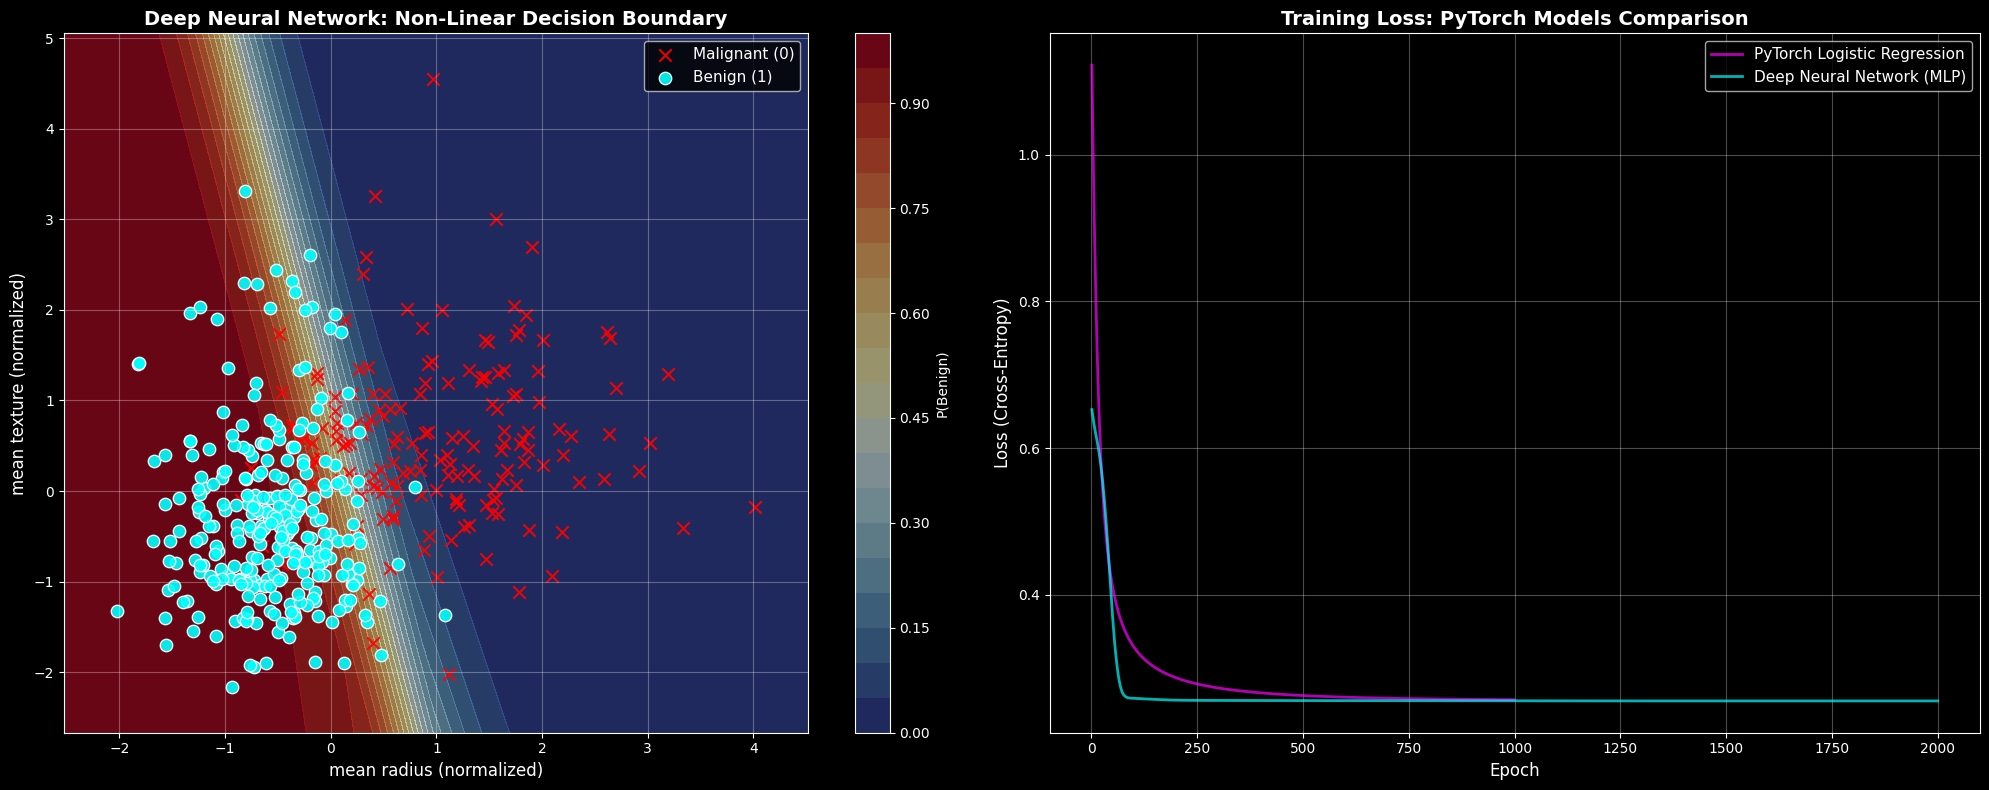

In [ ]:
# Create visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), dpi=100)

# Create mesh grid for decision boundary
x1_grid = np.linspace(X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5, 200)
x2_grid = np.linspace(X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5, 200)
X1_mesh, X2_mesh = np.meshgrid(x1_grid, x2_grid)
X_grid_torch = torch.FloatTensor(np.column_stack([X1_mesh.ravel(), X2_mesh.ravel()]))

# Compute probabilities using DNN
with torch.no_grad():
    prob_grid_dnn = model_dnn(X_grid_torch).numpy()

# Plot 1: Decision boundary with probability heatmap
contour = ax1.contourf(X1_mesh, X2_mesh, prob_grid_dnn.reshape(X1_mesh.shape),
                       levels=20, cmap='RdYlBu_r', alpha=0.6)
plt.colorbar(contour, ax=ax1, label='P(Benign)')

# Plot scatter points
ax1.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1],
            c='red', s=80, marker='x', label='Malignant (0)',
            edgecolors='white', linewidth=1.5, alpha=0.9)
ax1.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1],
            c='cyan', s=80, marker='o', label='Benign (1)',
            edgecolors='white', linewidth=1, alpha=0.9)

ax1.set_xlabel(breast_cancer_data.feature_names[feature_indices[0]] + ' (normalized)', fontsize=12)
ax1.set_ylabel(breast_cancer_data.feature_names[feature_indices[1]] + ' (normalized)', fontsize=12)
ax1.set_title('Deep Neural Network: Non-Linear Decision Boundary', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Training cost comparison
ax2.plot(range(1, len(cost_history_pytorch) + 1), cost_history_pytorch,
         'magenta', linewidth=2, label='PyTorch Logistic Regression', alpha=0.7)
ax2.plot(range(1, len(cost_history_dnn) + 1), cost_history_dnn,
         'cyan', linewidth=2, label='Deep Neural Network (MLP)', alpha=0.7)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss (Cross-Entropy)', fontsize=12)
ax2.set_title('Training Loss: PyTorch Models Comparison', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Summary table with all 5 algorithms
print("="*110)
print("COMPARISON: ALL ALGORITHMS")
print("="*110)
print(f"{'Algorithm':<30} {'Train Acc':<12} {'Test Acc':<12} {'Key Feature':<50}")
print("-"*110)
print(f"{'1. Perceptron':<30} {train_accuracy:.2f}%      {test_accuracy:.2f}%      {'Step activation, error count':<50}")
print(f"{'2. Adaline':<30} {train_accuracy_adaline:.2f}%      {test_accuracy_adaline:.2f}%      {'Linear activation, SSE cost':<50}")
print(f"{'3. Logistic Regression':<30} {train_accuracy_LoR:.2f}%      {test_accuracy_LoR:.2f}%      {'Sigmoid activation, Cross-Entropy cost':<50}")
print(f"{'4. PyTorch Logistic Reg':<30} {train_accuracy_pytorch:.2f}%      {test_accuracy_pytorch:.2f}%      {'Same as #3 but with PyTorch (automatic gradients)':<50}")
print(f"{'5. Deep Neural Network':<30} {train_accuracy_dnn:.2f}%      {test_accuracy_dnn:.2f}%      {'MLP: 3 hidden layers, ReLU, non-linear boundaries':<50}")
print("="*110)

print("\nKey Takeaways:")
print("  1. Algorithms 1-3: Simple linear classifiers (from scratch)")
print("  2. Algorithm 4: Same as #3 but using modern PyTorch framework")
print("  3. Algorithm 5: DEEP network with 3 hidden layers (can learn non-linear patterns!)")
print("  4. Logistic Regression gives probabilistic predictions (most interpretable)")
print("  5. Deep Neural Networks can capture complex, non-linear relationships .. you don't necessarily get the highest classification !")


COMPARISON: ALL ALGORITHMS
Algorithm                      Train Acc    Test Acc     Key Feature                                       
--------------------------------------------------------------------------------------------------------------
1. Perceptron                  87.91%      85.09%      Step activation, error count                      
2. Adaline                     88.35%      89.47%      Linear activation, SSE cost                       
3. Logistic Regression         89.45%      87.72%      Sigmoid activation, Cross-Entropy cost            
4. PyTorch Logistic Reg        89.45%      87.72%      Same as #3 but with PyTorch (automatic gradients) 
5. Deep Neural Network         89.89%      87.72%      MLP: 3 hidden layers, ReLU, non-linear boundaries 

Key Takeaways:
  1. Algorithms 1-3: Simple linear classifiers (from scratch)
  2. Algorithm 4: Same as #3 but using modern PyTorch framework
  3. Algorithm 5: DEEP network with 3 hidden layers (can learn non-linear patterns

C:\Users\mwafy\AppData\Local\Temp\ipykernel_33684\250587149.py:30: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1],


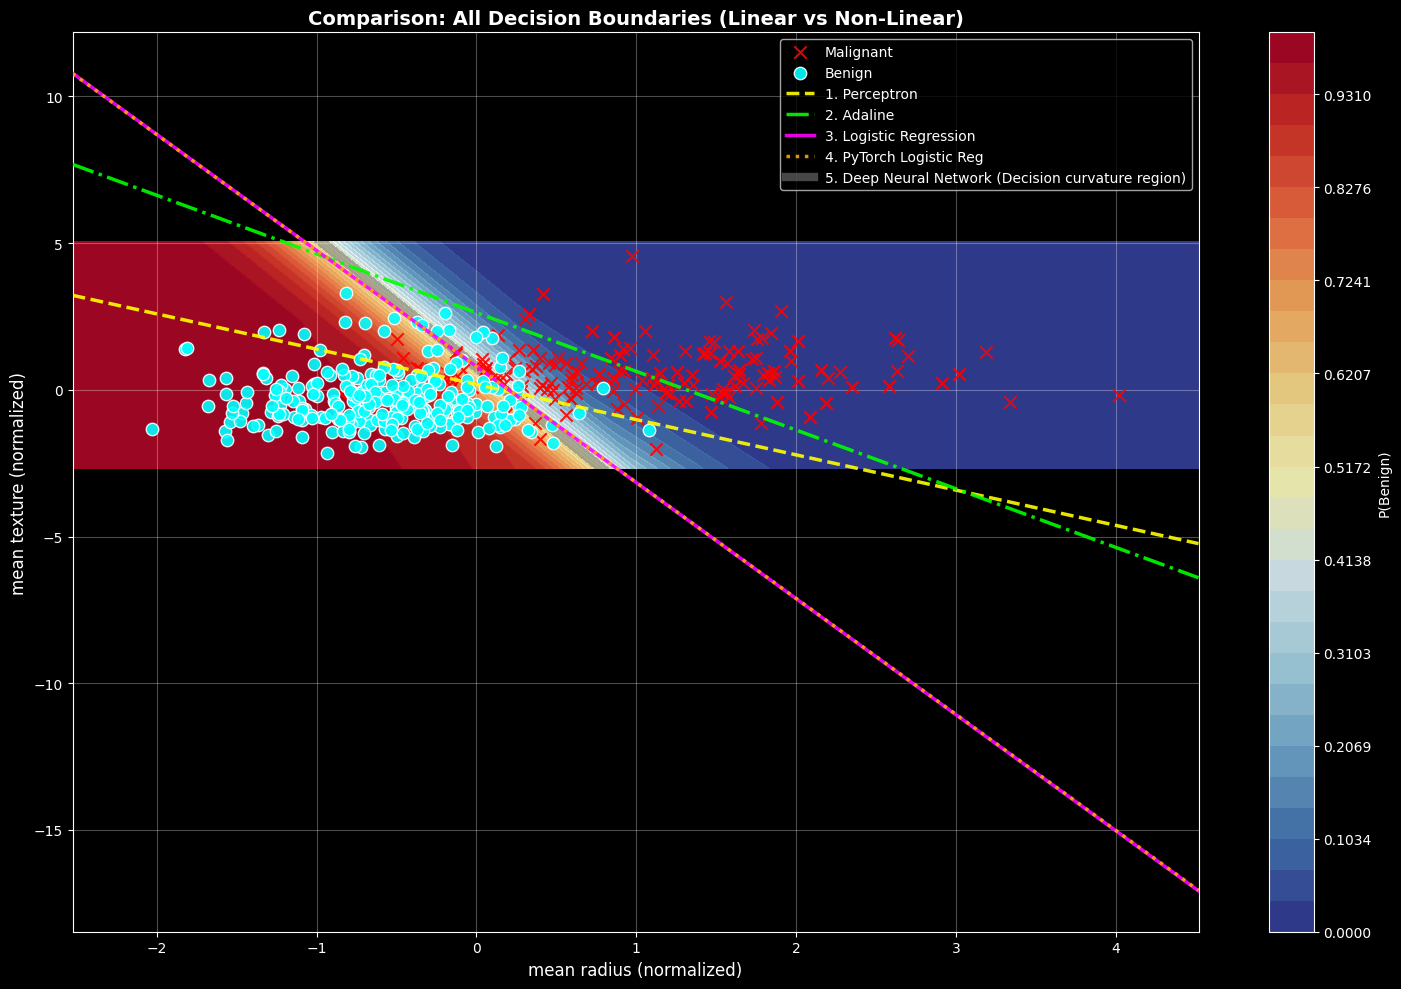

Notice:
  - The background heatmap shows the full probability space (color contours).
  - The dark grey band (Algorithm 5) highlights the non-linear curvature of the 0.5 decision region.
  - Algorithms 1-4: All linear boundaries (straight lines, very similar!)
  - Linear models work well when classes are linearly separable
  - Deep networks shine when data has complex, non-linear patterns


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Plot all decision boundaries together (including PyTorch models)
plt.figure(figsize=(15, 10), dpi=100)

# Create mesh grid for neural network boundaries
x1_grid = np.linspace(X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5, 300)
x2_grid = np.linspace(X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5, 300)
X1_mesh, X2_mesh = np.meshgrid(x1_grid, x2_grid)
X_grid_torch = torch.FloatTensor(np.column_stack([X1_mesh.ravel(), X2_mesh.ravel()]))

# Get DNN probabilities for background
with torch.no_grad():
    prob_grid_dnn_bg = model_dnn(X_grid_torch).numpy()

# 1. Plot DNN decision regions as a continuous probability heatmap background
contour_bg = plt.contourf(X1_mesh, X2_mesh, prob_grid_dnn_bg.reshape(X1_mesh.shape),
                          levels=np.linspace(0, 1, 30), cmap='RdYlBu_r', alpha=0.9)
plt.colorbar(contour_bg, label='P(Benign)')

# 2. Plot the curvature around the 0.5 decision boundary to visualize the boundary area decision
# This fills the area between 0.45 and 0.55 to highlight the non-linear separation region
# Note that here we make it wider so not exactly at 0.5 but this is to show the area in a clearer way
contour_band = plt.contourf(X1_mesh, X2_mesh, prob_grid_dnn_bg.reshape(X1_mesh.shape),
                            levels=[0.45, 0.55], colors=['#777777'], alpha=0.6, zorder=1) # Dark Grey

# Plot data points - high zorder
plt.scatter(X_train_scaled[y_train == 0, 0], X_train_scaled[y_train == 0, 1],
            c='red', s=80, marker='x', label='Malignant',
            edgecolors='white', linewidth=1.5, alpha=0.9, zorder=3)
plt.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1],
            c='cyan', s=80, marker='o', label='Benign',
            edgecolors='white', linewidth=1, alpha=0.9, zorder=3)

# Plot linear decision boundaries - very high zorder
x1_vals = np.linspace(X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5, 100)

# Perceptron boundary
x2_perceptron = -(w1 * x1_vals + b) / w2
plt.plot(x1_vals, x2_perceptron, color='yellow', linewidth=2.5,
         label='1. Perceptron', linestyle='--', alpha=0.9, zorder=4)

# Adaline boundary
x2_adaline = -(w1_adaline * x1_vals + b_adaline) / w2_adaline
plt.plot(x1_vals, x2_adaline, color='lime', linewidth=2.5,
         label='2. Adaline', linestyle='-.', alpha=0.9, zorder=4)

# Logistic Regression boundary (from scratch)
x2_logistic = -(w1_LoR * x1_vals + b_LoR) / w2_LoR
plt.plot(x1_vals, x2_logistic, color='magenta', linewidth=2.5,
         label='3. Logistic Regression', linestyle='-', alpha=0.9, zorder=4)

# PyTorch Logistic Regression boundary
x2_pytorch = -(w_pytorch[0] * x1_vals + b_pytorch) / w_pytorch[1]
plt.plot(x1_vals, x2_pytorch, color='orange', linewidth=2.5,
         label='4. PyTorch Logistic Reg', linestyle=':', alpha=0.9, zorder=4)

plt.plot([], [], color='#777777', linewidth=6, label='5. Deep Neural Network (Decision curvature region)', alpha=0.6)

plt.xlabel(breast_cancer_data.feature_names[feature_indices[0]] + ' (normalized)', fontsize=12)
plt.ylabel(breast_cancer_data.feature_names[feature_indices[1]] + ' (normalized)', fontsize=12)
plt.title('Comparison: All Decision Boundaries (Linear vs Non-Linear)', fontsize=14, fontweight='bold')
plt.legend(fontsize=10, loc='best')
plt.grid(True, alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

print("Notice:")
print("  - The background heatmap shows the full probability space (color contours).")
print("  - The dark grey band (Algorithm 5) highlights the non-linear curvature of the 0.5 decision region.")
print("  - Algorithms 1-4: All linear boundaries (straight lines, very similar!)")
print("  - Linear models work well when classes are linearly separable")
print("  - Deep networks shine when data has complex, non-linear patterns")

### Excercise

In [ ]:
feature_indices = [2, 3]
X = breast_cancer_data.data[:, feature_indices]
y = breast_cancer_data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [111]:
# Exercise 1: Logistic Regression from Scratch

# YOUR CODE HERE
np.random.seed(42)
w_LoR = np.random.rand(2) * 0.01
b_LoR = np.random.rand() * 0.01

lr_LoR = 0.1
epochs = 1000
cost_history_LoR = np.zeros(epochs)

cost_history_LoR = []


def sigmoid(x):
    res = 1 / (1 + np.exp(-x))
    return res

for epoch in range(epochs):
    z = np.dot(X_train_scaled, w_LoR) + b_LoR
    y_hat = sigmoid(z)

    error = y_hat - y_train
    w_lor_grads = (1 / len(X_train_scaled)) * np.dot(error, X_train_scaled)
    b_lor_grads = (1 / len(X_train_scaled)) * np.sum(error)

    w_LoR -= lr_LoR * w_lor_grads
    b_LoR -= lr_LoR * b_lor_grads

    bce_loss = - np.mean(y_train * np.log(y_hat + 1e-10) + (1 - y_train) * np.log(1 - y_hat + 1e-10))
    cost_history_LoR.append(bce_loss)

w1_LoR = w_LoR[0]
w2_LoR = w_LoR[1]

print(f"Final weights:")
print(f"  w1 = {w1_LoR:.4f}")
print(f"  w2 = {w2_LoR:.4f}")
print(f"  b  = {b_LoR:.4f}")

# Evaluation
# Training
linear_train_LoR = np.dot(X_train_scaled, w_LoR) + b_LoR
probs_train_LoR = sigmoid(linear_train_LoR)

train_preds_LoR = np.where(probs_train_LoR >= 0.5, 1, 0)
train_accuracy_LoR = np.mean(train_preds_LoR == y_train) * 100

# Testing
linear_test_LoR = np.dot(X_test_scaled, w_LoR) + b_LoR
probs_test_LoR = sigmoid(linear_test_LoR)

test_preds_LoR = np.where(probs_test_LoR >= 0.5, 1, 0)
test_accuracy_LoR = np.mean(test_preds_LoR == y_test) * 100

print("="*70)
print("EXERCISE 1: LOGISTIC REGRESSION FROM SCRATCH")
print("="*70)
print(f"Features: {breast_cancer_data.feature_names[feature_indices[0]]}")
print(f"          {breast_cancer_data.feature_names[feature_indices[1]]}")
print(f"\nTraining Accuracy: {train_accuracy_LoR:.2f}%")
print(f"Testing Accuracy:  {test_accuracy_LoR:.2f}%")
print(f"Final Cost: {cost_history_LoR[-1]:.6f}")
print("="*70)

Final weights:
  w1 = -2.3000
  w2 = -1.6522
  b  = 0.4689
EXERCISE 1: LOGISTIC REGRESSION FROM SCRATCH
Features: mean perimeter
          mean area

Training Accuracy: 88.57%
Testing Accuracy:  87.72%
Final Cost: 0.272899


### Exercise 2: Deep Neural Network with ALL 30 Features


In [100]:
X = breast_cancer_data.data
y = breast_cancer_data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [101]:
# Exercise 2: Deep Neural Network with ALL 30 Features
X_train_torch = torch.FloatTensor(X_train_scaled)
X_test_torch = torch.FloatTensor(X_test_scaled)
y_train_torch = torch.FloatTensor(y_train).unsqueeze(1)
y_test_torch = torch.FloatTensor(y_test).unsqueeze(1)

# YOUR CODE HERE
class DNN(nn.Module):
    def __init__(self, dims):
        super().__init__()
        self.fc1 = nn.Linear(dims, 15)
        self.fc2 = nn.Linear(15, 7)
        self.fc3 = nn.Linear(7, 3)
        self.fc4 = nn.Linear(3, 1)
        
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()
        
        self.dropout = nn.Dropout(p=0.1)
    
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        
        x = self.relu(self.fc3(x))
        x = self.dropout(x)
        
        x = self.sigmoid(self.fc4(x))
        return x

torch.manual_seed(42)
model_dnn = DNN(dims=30)

criterion = nn.BCELoss()
optimizer = optim.Adam(model_dnn.parameters(), lr=0.01, weight_decay=1e-4)

epochs = 1000
cost_history = []

for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model_dnn(X_train_torch)
    loss = criterion(outputs, y_train_torch)
    
    loss.backward()
    optimizer.step()
    
    cost_history.append(loss.item())
    
    if loss.item() < 1e-6:
        print(f"Converged at epoch {epoch + 1}!")
        break

with torch.no_grad():
    train_probs_dnn = model_dnn(X_train_torch).numpy()
    train_preds_dnn = (train_probs_dnn >= 0.5).astype(int).flatten()
    train_accuracy_dnn = np.mean(train_preds_dnn == y_train) * 100

    test_probs_dnn = model_dnn(X_test_torch).numpy()
    test_preds_dnn = (test_probs_dnn >= 0.5).astype(int).flatten()
    test_accuracy_dnn = np.mean(test_preds_dnn == y_test) * 100

# Count parameters
total_params_ex2 = sum(p.numel() for p in model_dnn.parameters())

print("="*70)
print("EXERCISE 2: DEEP NEURAL NETWORK (ALL 30 FEATURES)")
print("="*70)
print(f"Architecture: 30 → 8 → 6 → 4 → 1")
print(f"Total parameters: {total_params_ex2}")
print(f"\nTraining Accuracy: {train_accuracy_dnn:.2f}%")
print(f"Testing Accuracy:  {test_accuracy_dnn:.2f}%")
print(f"Final Loss: {cost_history[-1]:.6f}")
print("="*70)

EXERCISE 2: DEEP NEURAL NETWORK (ALL 30 FEATURES)
Architecture: 30 → 8 → 6 → 4 → 1
Total parameters: 605

Training Accuracy: 99.78%
Testing Accuracy:  94.74%
Final Loss: 0.036886


---

### Exercise 3: Visualize and Compare Results

Create visualizations comparing your two exercises:
1. Training cost curves (Exercise 1 vs Exercise 2)
2. Accuracy comparison bar chart
3. Exercise 1 decision boundary (2D plot)

**Complete the code below:**

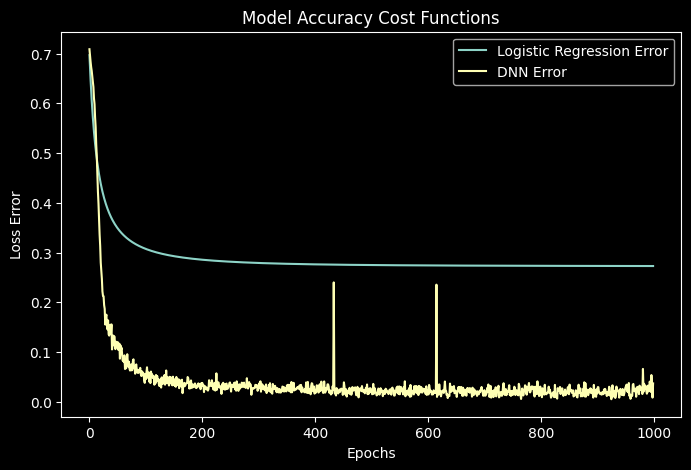

In [200]:
plt.figure(figsize=(8, 5))
plt.plot(cost_history_LoR, label="Logistic Regression Error")
plt.plot(cost_history, label="DNN Error")
plt.xlabel("Epochs")
plt.ylabel("Loss Error")
plt.title("Model Accuracy Cost Functions")
plt.legend()
plt.show()

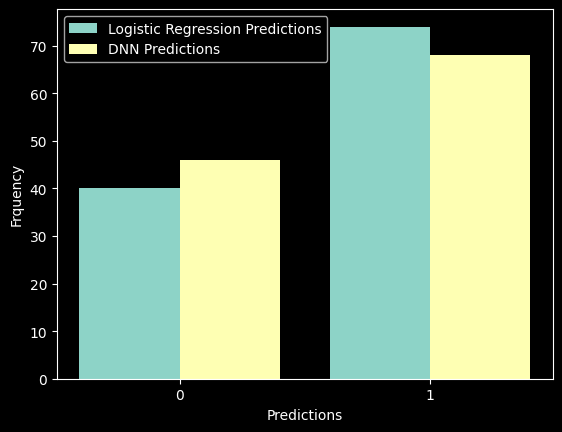

In [122]:
plt.hist([test_preds_LoR, test_preds_dnn], bins=2, label=["Logistic Regression Predictions", "DNN Predictions"])
plt.xticks([0.25, 0.75], ['0', '1'])
plt.xlabel("Predictions")
plt.ylabel("Frquency")
plt.legend()
plt.show()

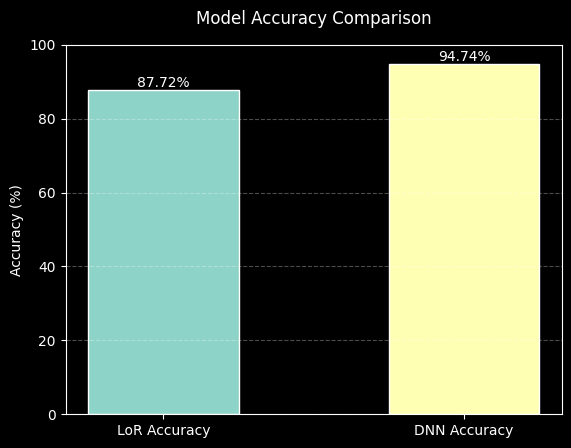

In [166]:
bars = plt.bar(["LoR Accuracy", "DNN Accuracy"], [test_accuracy_LoR, test_accuracy_dnn], color=["#8dd3c7", "#feffb3"], width=0.5, edgecolor="white")
plt.bar_label(bars, fmt="%.2f%%")
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison", pad=15)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()

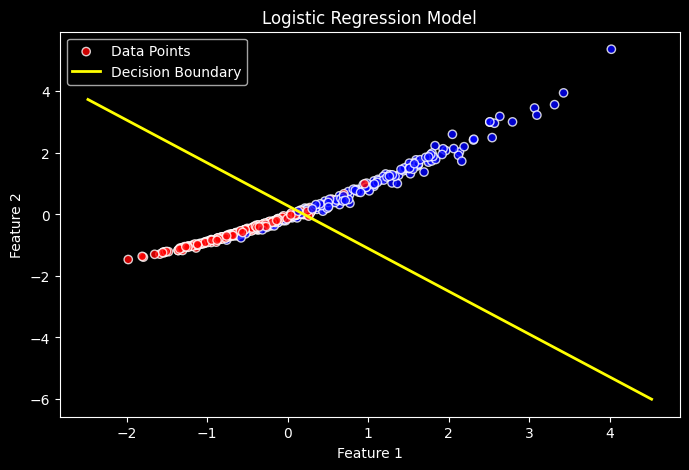

In [199]:
x_min = X_train_scaled[:, 0].min() - 0.5
x_max = X_train_scaled[:, 0].max() + 0.5

x_vals = np.linspace(x_min, x_max, 1000)
y_vals = - (w1_LoR * x_vals + b_LoR) / w2_LoR

plt.figure(figsize=(8, 5))
plt.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap="bwr", edgecolor="white", alpha=0.8, label="Data Points")
plt.plot(x_vals, y_vals, color="Yellow", linewidth=2, label="Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression Model")
plt.legend()
plt.show()

In [168]:
print("\n" + "="*70)
print("COMPARISON: EXERCISE 1 vs EXERCISE 2")
print("="*70)
print(f"Exercise 1 (2 features):   Test Accuracy = {test_accuracy_LoR:.2f}%")
print(f"Exercise 2 (30 features):  Test Accuracy = {test_accuracy_dnn:.2f}%")
print(f"\nImprovement: {test_accuracy_dnn - test_accuracy_LoR:.2f}% better with all features!")
print("="*70)


COMPARISON: EXERCISE 1 vs EXERCISE 2
Exercise 1 (2 features):   Test Accuracy = 87.72%
Exercise 2 (30 features):  Test Accuracy = 94.74%

Improvement: 7.02% better with all features!


---

## Congratulations!

<div dir="rtl" style="background-color: #1a1a2e; padding: 20px; border-radius: 10px; border-left: 5px solid #16213e; font-size: 18px;">
<strong>مبروك! خلصت  Week 4 بنجاح والحمد لله 🎉</strong>
</div>

### What You Learned Today:

✅ Applied **Perceptron** on real medical data  
✅ Applied **Adaline** with continuous cost function  
✅ Applied **Logistic Regression** with probabilistic predictions (from scratch AND PyTorch)  
✅ Built a **Deep Neural Network** with multiple hidden layers  
✅ Compared **linear vs non-linear** decision boundaries  
✅ Practiced implementing algorithms from scratch  
✅ Used **PyTorch** for modern deep learning  
✅ Saw how **all 30 features** improved accuracy

### Next Steps (Week 5):

- Data preprocessing techniques
- Model validation and cross-validation
- Regularization to prevent overfitting
- Hyperparameter tuning

Great work! You're now ready for building a more robust machine learning pipeline! 🚀